# Challenge 1
## Credit Risk Modelling (PD model)

---

### The business problem

Every client applying for a CLX loan must be assessed on their ability to repay. A consumer lender
automates this by estimating the **probability of default (PD)** for each application and using
that estimate in the approval / pricing decision.

Your task: **build, evaluate and defend a binary classification model that estimates PD** from the
provided application data, and then **hand your scores over to Challenge 2**, where you will turn
them into an actual lending policy.

### Ground rules

1. `TARGET = 1` means the loan **was not repaid (bad / default)**. `TARGET = 0` is a good loan.
2. **Holdout = May 2015.** You may not use May 2015 rows for training, feature selection, encoding
   statistics, or hyper-parameter tuning. Not once. Not "just to check".
3. **Train at least two different algorithms** and compare them (e.g. logistic regression on WOE
   vs. gradient boosting). One of them must be simple enough that you can explain it to a
   non-technical stakeholder.
4. **Do NOT use these columns as features:**
   `AMOUNT_VND`, `TENOR_MONTHS`, `INTEREST_RATE`, `MONTHLY_INSTALLMENT`, `PRODUCT_GROUP`.
   They describe the contract that the **previous** underwriting policy granted, and that policy
   already knew something about the client's risk. Using them leaks the old decision into your
   model. They exist in this dataset for **Challenge 2** only.
5. This notebook gives you **structure and a few helper functions**, not a solution. Every
   `# TODO` is yours. You are expected to write substantially more code than you find here.

### What you must produce

| # | Deliverable | Notes |
|---|---|---|
| 1 | This notebook, completed and runnable top to bottom | clean, commented, no dead cells |
| 2 | `results/pd_predictions.csv` | `ID_APPLICATION, PD` for **all May 2015 applications** — Challenge 2 depends on this file |

> Do **not** burn your 3.5 hours squeezing out the last 0.5 Gini point. We care far more about how
> you frame the problem, what you notice in the data, and how you justify your choices.

## 0. Environment & data load

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

DATA = "../data/training_data.csv.gz"   # not in the repository: see data/README.md
HOLDOUT_MONTH = "2015-05"

df = pd.read_csv(DATA, parse_dates=["TIME"])
print(df.shape)
df.head()

(200000, 61)


,ID_APPLICATION,TIME,NUMERICAL_0,NUMERICAL_1,NUMERICAL_2,NUMERICAL_3,NUMERICAL_4,NUMERICAL_5,NUMERICAL_6,NUMERICAL_7,NUMERICAL_8,NUMERICAL_9,NUMERICAL_10,NUMERICAL_11,NUMERICAL_12,NUMERICAL_13,NUMERICAL_14,NUMERICAL_15,NUMERICAL_16,NUMERICAL_17,NUMERICAL_18,NUMERICAL_19,NUMERICAL_20,NUMERICAL_21,NUMERICAL_22,NUMERICAL_23,NUMERICAL_24,NUMERICAL_25,NUMERICAL_26,NUMERICAL_27,NUMERICAL_28,NUMERICAL_29,NUMERICAL_30,NUMERICAL_31,NUMERICAL_32,NUMERICAL_33,NUMERICAL_34,NUMERICAL_35,NUMERICAL_36,NUMERICAL_37,NUMERICAL_38,NUMERICAL_39,NUMERICAL_40,NUMERICAL_41,CATEGORICAL_0,CATEGORICAL_1,CATEGORICAL_2,CATEGORICAL_3,CATEGORICAL_4,CATEGORICAL_5,CATEGORICAL_6,CATEGORICAL_7,CATEGORICAL_8,CATEGORICAL_9,CATEGORICAL_10,TARGET,AMOUNT_VND,TENOR_MONTHS,INTEREST_RATE,MONTHLY_INSTALLMENT,PRODUCT_GROUP
0,0,2014-06-20 11:03:04,0.548205,6.273278,-0.557716,-0.086105,-0.726799,-0.523021,0.571528,0.176804,-0.838352,-0.103013,1.158706,-0.212026,-0.234368,-0.124713,-0.081091,1.290278,-0.035170,0.124484,-1.034189,-1.644278,0.679013,1.281491,0.788627,-0.460796,1.390557,0.881212,0.638268,-0.960688,-0.377680,-0.580543,2.501600,0.082666,1.459566,-1.384292,-0.315971,1.270519,-1.496014,-0.632267,-1.582633,-1.256936,3.030291,1.433575,JJUFY,DVSOM,AB,DF,JK,TR,C,A,BB,AA,NFAYV,1,6300000,3,0.4279,2251514,CLX_MICRO
1,1,2014-06-20 11:05:39,-0.640991,5.662506,0.050086,0.233125,0.482266,0.085460,-0.552130,-0.017248,-0.965931,0.849677,0.157380,1.101467,0.646058,-0.009837,0.393702,0.531926,-1.424797,1.915330,1.351310,-0.358253,1.978715,-0.271216,-0.232454,0.703819,-0.237303,1.083354,-1.390248,1.309810,0.270448,-1.479979,-0.491356,1.365831,0.484533,-0.206937,0.642391,-1.296599,0.826529,1.281990,-1.384296,0.434467,-1.481401,-0.022775,IMFRD,OMFDE,AA,DF,JK,WE,A,A,AA,BB,NFAYV,0,54400000,30,0.4005,2897889,CLX_MID
2,2,2014-06-20 11:07:00,0.394312,5.782492,-0.421450,0.756713,0.408276,0.327221,-0.905630,-0.941560,-0.428490,-0.600134,0.754308,0.853577,-1.403067,-1.359309,1.462703,-0.358459,-0.277432,0.617662,0.014705,0.983699,-0.863582,-0.801310,-0.156739,-0.822613,-0.590275,0.757495,-0.133249,-0.634880,0.358560,0.103737,-1.251672,-0.154054,-1.052260,-2.202368,0.615709,0.415903,1.708162,-0.464763,-1.816730,-0.491451,3.040916,0.128277,FPTCW,DVSOM,AB,AS,GH,TR,C,C,BB,BB,NFAYV,0,20000000,24,0.3724,1194133,CLX_SMALL
3,3,2014-06-20 11:09:38,-0.320658,4.736009,0.334894,1.092682,0.646294,1.541267,0.966884,-0.790725,-0.104912,-0.085229,-0.131544,0.384675,-1.384116,0.088636,1.201209,-0.697751,0.085957,-0.724011,0.127451,0.051323,-1.294005,-0.381061,-1.701719,1.857113,2.830627,0.643933,0.672402,1.563362,-0.581834,0.810481,-0.294676,0.135158,0.883987,-0.144025,0.552004,-0.270202,-0.769074,-1.867523,0.021831,-0.323530,0.667023,-0.134636,UQPEF,DVSOM,AB,AS,GH,TR,A,A,AA,BB,HNPAK,0,38200000,30,0.3549,1938244,CLX_SMALL
4,4,2014-06-20 11:11:10,0.433235,5.323432,0.826207,0.718267,-1.627944,2.203108,0.420342,-0.223997,0.822779,0.602888,0.612547,-0.451226,2.490127,-0.467325,-0.019195,-0.052899,1.596603,0.072862,-0.148237,-1.771107,-0.429010,0.253337,-0.253680,-0.383013,0.303515,0.914466,0.666860,-0.410129,0.538753,1.028974,0.506040,-0.682719,0.619396,-2.250196,0.410428,1.389805,1.094239,-0.879487,1.250560,-0.162953,-1.004300,-0.472046,IMFRD,OMFDE,NaN,NaN,NaN,NaN,B,B,BB,BB,NFAYV,0,49200000,18,0.3570,3569711,CLX_MID


In [2]:
# Column groups you will need all the way through.
ID_COL     = "ID_APPLICATION"
TARGET     = "TARGET"
NUM_COLS   = [c for c in df.columns if c.startswith("NUMERICAL_")]
CAT_COLS   = [c for c in df.columns if c.startswith("CATEGORICAL_")]
CONTRACT   = ["AMOUNT_VND", "TENOR_MONTHS", "INTEREST_RATE",
              "MONTHLY_INSTALLMENT", "PRODUCT_GROUP"]   # <-- OFF LIMITS in Challenge 1

FEATURES = NUM_COLS + CAT_COLS
print(f"{len(NUM_COLS)} numerical, {len(CAT_COLS)} categorical, {len(FEATURES)} candidate features")

42 numerical, 11 categorical, 53 candidate features


## 1. Data audit — before you model anything

Spend real time here. In a credit portfolio, most of the value comes from understanding the data,
not from the algorithm.

**Do at least this:**

- Row count, date range, duplicates on `ID_APPLICATION`.
- Overall bad rate, and **bad rate by month** — is the target stable over the year?
- Application **volume by month** — are all months comparable in size?
- Missing-value rate per feature. Is missingness itself informative (does bad rate differ between
  missing and non-missing)? Some of these features have deliberately nasty missing patterns.
- Cardinality and category frequencies for every `CATEGORICAL_*`. Are there rare levels? Do new
  levels appear in later months?
- Distribution summaries for `NUMERICAL_*`: outliers, constants, near-duplicates, suspicious spikes.

**Questions to be able to answer at the defence:** Which features are unusable and why? Which
features changed behaviour during the observation window? Would you have caught that with a
train/test random split?

In [3]:
# --- 1.1 Basic audit ---------------------------------------------------------------------------
df["MONTH"] = df["TIME"].dt.to_period("M").astype(str)

print(f"rows             : {len(df):,}")
print(f"date range       : {df['TIME'].min()}  ->  {df['TIME'].max()}")
print(f"duplicate IDs    : {df[ID_COL].duplicated().sum()}   | fully duplicated rows: {df.duplicated().sum()}")
print(f"overall bad rate : {df[TARGET].mean():.4f}")
print("column types     :", df.dtypes.astype(str).value_counts().to_dict())
print("contract columns (never used as features here):", CONTRACT)

# Hygiene: every DECISION below (drop / keep / repair a feature) is taken on the DEVELOPMENT period
# only (< 2015-05). May 2015 features are used for PSI (no target needed); May's TARGET is not used
# until the single scoring step in section 7.
dev_audit = df[df["MONTH"] < HOLDOUT_MONTH]
print(f"development rows : {len(dev_audit):,}  ({dev_audit['MONTH'].min()} .. {dev_audit['MONTH'].max()})")

rows             : 200,000
date range       : 2014-06-20 11:03:04  ->  2015-05-31 23:23:25


duplicate IDs    : 0   | fully duplicated rows: 0
overall bad rate : 0.3589
column types     : {'float64': 43, 'str': 13, 'int64': 5, 'datetime64[us]': 1}
contract columns (never used as features here): ['AMOUNT_VND', 'TENOR_MONTHS', 'INTEREST_RATE', 'MONTHLY_INSTALLMENT', 'PRODUCT_GROUP']
development rows : 182,024  (2014-06 .. 2015-04)


In [4]:
# --- HELPER (given): monthly target and volume profile -----------------------
def monthly_profile(frame, target=TARGET, time_col="TIME"):
    """Volume and bad rate per calendar month — your first sanity check on any dataset."""
    m = frame.assign(_m=frame[time_col].dt.to_period("M"))
    out = m.groupby("_m").agg(n=(target, "size"), bad_rate=(target, "mean"))
    out["share"] = out["n"] / out["n"].sum()
    return out

monthly_profile(df).round(4)

,n,bad_rate,share
_m,,,
2014-06,6119,0.3594,0.0306
2014-07,17943,0.3602,0.0897
2014-08,17996,0.3575,0.0900
2014-09,17483,0.3605,0.0874
2014-10,17893,0.3547,0.0895
2014-11,17222,0.3557,0.0861
2014-12,17975,0.3564,0.0899
2015-01,17916,0.3595,0.0896
2015-02,16183,0.3590,0.0809


**Reading of the monthly profile.** The portfolio looks calm: ~18k applications per month (June 2014 is a
partial month starting on the 20th; Feb 2015 is short), and the bad rate sits at ~36% in every month
(35.5%–36.3%). A *flat* target is exactly what makes the instabilities below dangerous: nothing at
portfolio level warns you that individual features have changed meaning.

,n_missing,miss_rate,bad_rate_missing,bad_rate_present,gap
feature,,,,,
NUMERICAL_40,54468,0.2992,0.4523,0.3184,0.1338
CATEGORICAL_2,72709,0.3994,0.4222,0.3161,0.1060
CATEGORICAL_4,72709,0.3994,0.4222,0.3161,0.1060
CATEGORICAL_3,72709,0.3994,0.4222,0.3161,0.1060
CATEGORICAL_5,72709,0.3994,0.4222,0.3161,0.1060
NUMERICAL_10,56251,0.3090,0.3576,0.3589,-0.0013


6 of 53 features have missing values; the other 47 are complete.



CATEGORICAL_2..5 missing together in the same rows : True | shared missing rate 0.399
corr(NUMERICAL_40 missing, CATEGORICAL_2 missing)    : -0.001


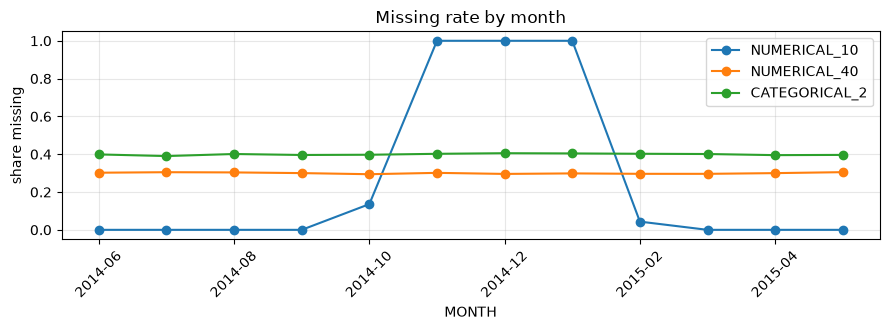

In [5]:
# --- 1.2 Missing-value report (development period) -----------------------------------------------
rows = []
for c in FEATURES:
    m = dev_audit[c].isna()
    if m.any():
        rows.append(dict(feature=c, n_missing=int(m.sum()), miss_rate=m.mean(),
                         bad_rate_missing=dev_audit.loc[m, TARGET].mean(),
                         bad_rate_present=dev_audit.loc[~m, TARGET].mean()))
miss = pd.DataFrame(rows).set_index("feature")
miss["gap"] = miss["bad_rate_missing"] - miss["bad_rate_present"]
display(miss.sort_values("gap", key=abs, ascending=False).round(4))
print(f"{len(miss)} of {len(FEATURES)} features have missing values; the other {len(FEATURES)-len(miss)} are complete.")

cat_na = ["CATEGORICAL_2", "CATEGORICAL_3", "CATEGORICAL_4", "CATEGORICAL_5"]
print("\nCATEGORICAL_2..5 missing together in the same rows :",
      (dev_audit[cat_na].isna().nunique(axis=1) == 1).all(),
      f"| shared missing rate {dev_audit[cat_na[0]].isna().mean():.3f}")
print("corr(NUMERICAL_40 missing, CATEGORICAL_2 missing)    :",
      round(dev_audit["NUMERICAL_40"].isna().astype(int).corr(dev_audit["CATEGORICAL_2"].isna().astype(int)), 3))

# Missingness over time: is it structural (constant) or an incident (a hole in the calendar)?
miss_by_month = df[FEATURES].isna().groupby(df["MONTH"]).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
miss_by_month[["NUMERICAL_10", "NUMERICAL_40", "CATEGORICAL_2"]].plot(ax=ax, marker="o")
ax.set_title("Missing rate by month"); ax.set_ylabel("share missing"); ax.grid(alpha=.3)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

**Missing-value findings**

* **`NUMERICAL_40`** (30% missing) and the block **`CATEGORICAL_2..5`** (40% missing, always missing *together*)
  have a constant missing rate every month → *structural* missingness, and it is **informative**: bad rate is
  ~0.42–0.45 when missing vs ~0.32 when present. They get an explicit "missing" treatment (own WOE bin /
  `MISS_*` flag).
* **`NUMERICAL_10`** is the opposite: 31% missing in the development rows, but the missingness is **one incident** – the field is
  100% empty for Nov-2014 → Jan-2015 (and partly Oct / Feb) and fully populated before and after (incl. May 2015).
  Its bad rate when "missing" equals the portfolio average (0.358), i.e. *the NaN carries no information* – it is a
  data-source outage, not a client behaviour. Treat as an outage to be repaired, not as a signal.

In [6]:
# --- 1.3 Categorical profile -----------------------------------------------------------------------
rows, level_rows = [], []
may_levels = df[df["MONTH"] == HOLDOUT_MONTH]
for c in CAT_COLS:
    s = dev_audit[c].fillna("NA")
    share = s.value_counts(normalize=True)
    br = dev_audit.groupby(s)[TARGET].mean()
    month_share = pd.crosstab(dev_audit["MONTH"], s, normalize="index")
    lv_dev, lv_may = set(s), set(may_levels[c].fillna("NA"))        # level EXISTENCE only: no target used
    rows.append(dict(feature=c, n_levels=s.nunique(), min_level_share=share.min(),
                     bad_rate_min=br.min(), bad_rate_max=br.max(),
                     max_monthly_share_swing=(month_share.max() - month_share.min()).max(),
                     levels_new_in_May=sorted(lv_may - lv_dev), levels_absent_in_May=sorted(lv_dev - lv_may)))
    for lv in share.index:
        level_rows.append(dict(feature=c, level=lv, share=share[lv], bad_rate=br[lv]))
cat_prof = pd.DataFrame(rows).set_index("feature")
display(cat_prof.round(3))
print("Rare levels (< 1% share):", [r for r in level_rows if r["share"] < 0.01] or "none")

,n_levels,min_level_share,bad_rate_min,bad_rate_max,max_monthly_share_swing,levels_new_in_May,levels_absent_in_May
feature,,,,,,,
CATEGORICAL_0,5,0.199,0.357,0.361,0.021,[],[]
CATEGORICAL_1,3,0.332,0.229,0.439,0.016,[],[]
CATEGORICAL_2,3,0.299,0.264,0.422,0.015,[],[]
CATEGORICAL_3,3,0.299,0.266,0.422,0.015,[],[]
CATEGORICAL_4,3,0.299,0.263,0.422,0.015,[],[]
CATEGORICAL_5,3,0.300,0.264,0.422,0.015,[],[]
CATEGORICAL_6,3,0.287,0.252,0.451,0.013,[],[]
CATEGORICAL_7,3,0.259,0.146,0.504,0.205,[],[A]
CATEGORICAL_8,2,0.499,0.305,0.412,0.011,[],[]


Rare levels (< 1% share): none


**Categorical findings** – all categoricals are low-cardinality (2–5 levels) and **no level is rare** (smallest
share ≈ 20%), so rare-level grouping is a safeguard rather than a necessity here. Two things stand out:

1. **`CATEGORICAL_7`: level `A` (the riskiest, bad rate 50%) exists in the development period but is *absent in
   May 2015*** (`levels_absent_in_May`). Its monthly share collapses from ~50% to 30% in April and 0% in May.
   This is a re-definition, analysed in section 2.
2. **`CATEGORICAL_9`** shows nothing in this table (two balanced levels, stable shares) – yet it is the feature that
   hides the nastiest problem. Level shares are perfectly stable, so a *distribution* test cannot see it. See section 2.

constant features             : none
features with a spike (>5% on one value): none
max monthly std ratio         : 1.034


max |corr| between two numerics: ('NUMERICAL_10', 'NUMERICAL_41') 0.649 -> no near-duplicates


,count,mean,std,min,50%,max,skew,top_value_share,pct_beyond_4sd,n_unique,uni_gini,monthly_std_ratio
NUMERICAL_10,125773.0,0.001,1.001,-4.350,0.001,4.562,0.000,0.0,0.007,125773,0.342,1.014
NUMERICAL_41,182024.0,-0.000,1.000,-4.465,-0.001,4.087,0.004,0.0,0.003,182024,0.220,1.018
NUMERICAL_40,127556.0,-0.010,2.000,-8.985,-0.017,9.599,0.006,0.0,0.005,127556,0.164,1.026
NUMERICAL_30,182024.0,0.002,1.001,-4.357,-0.003,4.518,0.002,0.0,0.005,182024,0.157,1.022
NUMERICAL_34,182024.0,-0.001,1.000,-4.162,0.002,4.372,-0.012,0.0,0.004,182024,0.006,1.018
NUMERICAL_28,182024.0,-0.000,0.997,-4.334,0.001,4.177,-0.010,0.0,0.003,182024,-0.006,1.027
NUMERICAL_37,182024.0,-0.001,0.999,-4.411,0.001,5.014,-0.004,0.0,0.004,182024,-0.006,1.016
NUMERICAL_29,182024.0,0.002,0.998,-4.658,0.001,4.660,-0.004,0.0,0.007,182024,-0.006,1.023


Numericals with |univariate Gini| < 0.03 : 38 of 42


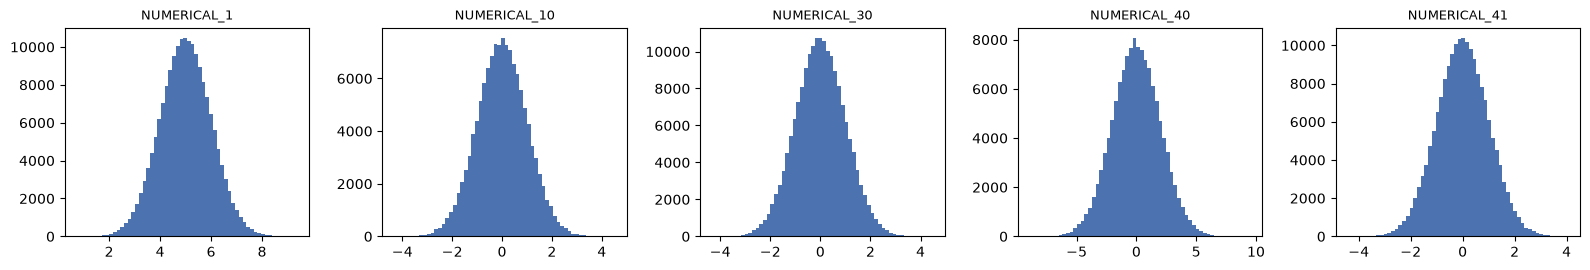

In [7]:
# --- 1.4 Numerical profile -----------------------------------------------------------------------
from sklearn.metrics import roc_auc_score

num = dev_audit[NUM_COLS]
prof = num.describe().T[["count", "mean", "std", "min", "50%", "max"]]
prof["skew"] = num.skew()
prof["top_value_share"] = [num[c].value_counts(normalize=True).iloc[0] for c in NUM_COLS]    # spike check
prof["pct_beyond_4sd"] = [((num[c] - num[c].mean()).abs() > 4 * num[c].std()).mean() * 100 for c in NUM_COLS]
prof["n_unique"] = num.nunique()
# marginal signal: univariate Gini (NaN rows ignored)
prof["uni_gini"] = [2 * roc_auc_score(dev_audit.loc[num[c].notna(), TARGET], num[c].dropna()) - 1 for c in NUM_COLS]
# constant inside some months? -> ratio of the largest to smallest monthly std
mstd = dev_audit.groupby("MONTH")[NUM_COLS].std()
prof["monthly_std_ratio"] = (mstd.max() / mstd.min()).values

print("constant features             :", list(prof.index[prof["n_unique"] <= 1]) or "none")
print("features with a spike (>5% on one value):", list(prof.index[prof["top_value_share"] > 0.05]) or "none")
print("max monthly std ratio         :", round(prof["monthly_std_ratio"].max(), 3))
corr = num.corr().abs().where(np.triu(np.ones((len(NUM_COLS),) * 2, dtype=bool), 1))
pairs = corr.stack().sort_values(ascending=False)
print("max |corr| between two numerics:", pairs.index[0], round(pairs.iloc[0], 3), "-> no near-duplicates" if pairs.iloc[0] < .9 else "")
display(prof.sort_values("uni_gini", key=abs, ascending=False).head(8).round(3))
print("Numericals with |univariate Gini| < 0.03 :", int((prof["uni_gini"].abs() < .03).sum()), "of", len(NUM_COLS))

fig, axes = plt.subplots(1, 5, figsize=(16, 2.8))
for ax, c in zip(axes, ["NUMERICAL_1", "NUMERICAL_10", "NUMERICAL_30", "NUMERICAL_40", "NUMERICAL_41"]):
    ax.hist(dev_audit[c].dropna(), bins=60, color="#4c72b0"); ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

**Numerical findings** – 42 numerics, all roughly standard-normal (anonymised / pre-scaled), no constants, no
spikes at single values, no impossible values, no outliers beyond ~5 sd, no near-duplicate pairs and no feature that
is constant inside a month. `NUMERICAL_1` is centred on 5 (not 0) and `NUMERICAL_40` has twice the spread.
The key observation is **how little marginal signal there is**: only `NUMERICAL_10`, `_30`, `_40`, `_41` show a
meaningful univariate Gini; most of the others are ≈ 0 on their own. Some of those (e.g. `NUMERICAL_1`, `_32`)
nevertheless matter to a tree model, which means their effect is *non-linear or interaction-based* – a point that
will matter when comparing a WOE-logistic model with gradient boosting.

## 2. Feature stability in time

The assignment brief warns you: *"Features in the provided dataset can suffer from various issues
concerning stability in time."* This is the single most important trap in this challenge, and it is
exactly what happens in a real portfolio — a data source changes, a field is re-defined, a channel
stops sending a value.

A feature that is unstable between training period and holdout will look great in cross-validation
and then quietly destroy your model in production.

**Do this:**

1. Compute **PSI (Population Stability Index)** for every feature, early months vs. May 2015.
2. Also look at the **bad rate by feature bin, per month** — a feature can be stable in
   distribution but flip its relationship to the target (that is worse).
3. Decide a rule for dropping / repairing features and **write down the rule**. "PSI > 0.25 → drop"
   is a defensible rule. "I dropped what looked odd" is not.

Rule of thumb: PSI < 0.10 stable · 0.10–0.25 watch · > 0.25 unstable.

In [8]:
# --- HELPER (given): Population Stability Index ------------------------------
def psi(expected, actual, bins=10, eps=1e-6):
    """PSI between two 1-D samples. Numeric input is binned on `expected` quantiles;
    non-numeric input is compared level by level. NaN is treated as its own bucket."""
    expected = pd.Series(expected)
    actual = pd.Series(actual)

    if pd.api.types.is_numeric_dtype(expected):
        edges = np.unique(np.nanquantile(expected.dropna(), np.linspace(0, 1, bins + 1)))
        if len(edges) < 3:
            return 0.0
        edges[0], edges[-1] = -np.inf, np.inf
        e = pd.cut(expected, edges).cat.add_categories("NA").fillna("NA")
        a = pd.cut(actual, edges).cat.add_categories("NA").fillna("NA")
    else:
        e = expected.fillna("NA").astype(str)
        a = actual.fillna("NA").astype(str)

    e_share = e.value_counts(normalize=True)
    a_share = a.value_counts(normalize=True).reindex(e_share.index).fillna(0.0)
    e_share, a_share = e_share + eps, a_share + eps
    return float(((a_share - e_share) * np.log(a_share / e_share)).sum())

In [9]:
# --- 2.1 PSI of every feature: base = development period, target = May 2015 ------------------------
dev_psi = df[df["MONTH"] < HOLDOUT_MONTH]
may_psi = df[df["MONTH"] == HOLDOUT_MONTH]

# A month in which some feature is (almost) fully missing is a data-source OUTAGE, not a population shift.
# Left in the base, it would make the outage feature look "unstable" although May is perfectly healthy.
outage_flags = (miss_by_month > 0.90)
OUTAGE_MONTHS = [m for m in outage_flags.index[outage_flags.any(axis=1)] if m < HOLDOUT_MONTH]
OUTAGE_FEATS = list(outage_flags.columns[outage_flags.any(axis=0)])
base_clean = dev_psi[~dev_psi["MONTH"].isin(OUTAGE_MONTHS)]
print("outage months :", OUTAGE_MONTHS, "| outage features:", OUTAGE_FEATS)

psi_tbl = pd.DataFrame({
    "psi_dev_vs_may": {f: psi(dev_psi[f], may_psi[f]) for f in FEATURES},
    "psi_ex_outage":  {f: psi(base_clean[f], may_psi[f]) for f in FEATURES},
})
psi_tbl["verdict"] = pd.cut(psi_tbl["psi_ex_outage"], [-1, .10, .25, np.inf],
                            labels=["stable", "watch", "unstable"]).astype(str)
display(psi_tbl.sort_values("psi_ex_outage", ascending=False).head(8).round(4))
print(psi_tbl["verdict"].value_counts().to_dict())

outage months : ['2014-11', '2014-12', '2015-01'] | outage features: ['NUMERICAL_10']


,psi_dev_vs_may,psi_ex_outage,verdict
CATEGORICAL_7,6.6082,6.4815,unstable
NUMERICAL_10,4.0213,0.2471,watch
NUMERICAL_27,0.0016,0.0015,stable
NUMERICAL_18,0.0012,0.0014,stable
NUMERICAL_29,0.0010,0.0011,stable
NUMERICAL_26,0.0011,0.0011,stable
NUMERICAL_8,0.0011,0.0010,stable
NUMERICAL_13,0.0008,0.0010,stable


{'stable': 51, 'watch': 1, 'unstable': 1}


**PSI reading.** Only **`CATEGORICAL_7`** is flagged *unstable* (PSI ≫ 0.25: level `A` disappears and its mass is
re-distributed to `B`/`C`). `NUMERICAL_10` has a large PSI against the *raw* development period, but that is purely the
outage months sitting in the base – against the outage-free base it is stable, so it is not an instability in May.
Everything else is < 0.01. **If PSI were the only test we would stop here and keep `CATEGORICAL_9`.** The next test is
the one that matters.

In [10]:
# --- 2.2 Relationship drift: does the feature -> bad-rate mapping stay put, week after week? ---------
def weekly_relationship_drift(frame, feats, y=TARGET, n_bins=5, min_rows=1000):
    """For each feature and calendar week: weighted mean |bad rate of the bin in that week  minus  bad rate of
    the same bin in ALL OTHER weeks|.  Numerics -> quintile bins + NA bin, categoricals -> levels.
    Pure noise gives ~0.01-0.03; a flipped / re-coded feature gives 0.2-0.4. PSI cannot see this: the
    distribution of the feature may not move at all."""
    wk = frame["TIME"].dt.to_period("W").astype(str).to_numpy()
    yv = frame[y].to_numpy()
    out = {}
    for f in feats:
        x = frame[f]
        if pd.api.types.is_numeric_dtype(x):
            e = np.unique(np.nanquantile(x.dropna(), np.linspace(0, 1, n_bins + 1)))
            e[0], e[-1] = -np.inf, np.inf
            b = np.where(x.isna(), "NA", np.digitize(x.to_numpy(float), e[1:-1]).astype(str))
        else:
            b = x.fillna("NA").astype(str).to_numpy()
        g = pd.DataFrame({"wk": wk, "b": b, "y": yv})
        n_wb = g.groupby(["wk", "b"])["y"].size().unstack(fill_value=0)
        k_wb = g.groupby(["wk", "b"])["y"].sum().unstack(fill_value=0)
        ref_n, ref_k = n_wb.sum() - n_wb, k_wb.sum() - k_wb              # leave-one-week-out reference
        diff = (k_wb / n_wb.replace(0, np.nan) - ref_k / ref_n.replace(0, np.nan)).abs()
        w = n_wb.where(diff.notna(), 0)
        drift = (diff.fillna(0) * n_wb).sum(axis=1) / w.sum(axis=1)
        drift[n_wb.sum(axis=1) < min_rows] = np.nan
        out[f] = drift
    return pd.DataFrame(out)

drift = weekly_relationship_drift(dev_psi, FEATURES)
REL_DROP, REL_WATCH = 0.10, 0.05
drift_sum = pd.DataFrame({
    "max_drift": drift.max(),
    "break_week": [drift.index[drift[f] > REL_DROP][0] if (drift[f] > REL_DROP).any() else "" for f in drift.columns],
    "weeks_above_threshold": (drift > REL_DROP).sum(),
})
display(drift_sum.sort_values("max_drift", ascending=False).head(8).round(3))
print("median max_drift over the remaining features (noise floor):",
      round(drift_sum["max_drift"].sort_values().iloc[:-3].median(), 3))

,max_drift,break_week,weeks_above_threshold
CATEGORICAL_9,0.358,2015-04-20/2015-04-26,2
CATEGORICAL_7,0.139,2015-04-20/2015-04-26,2
NUMERICAL_12,0.039,,0
CATEGORICAL_0,0.034,,0
NUMERICAL_9,0.031,,0
NUMERICAL_6,0.031,,0
NUMERICAL_33,0.028,,0
NUMERICAL_40,0.028,,0


median max_drift over the remaining features (noise floor): 0.025


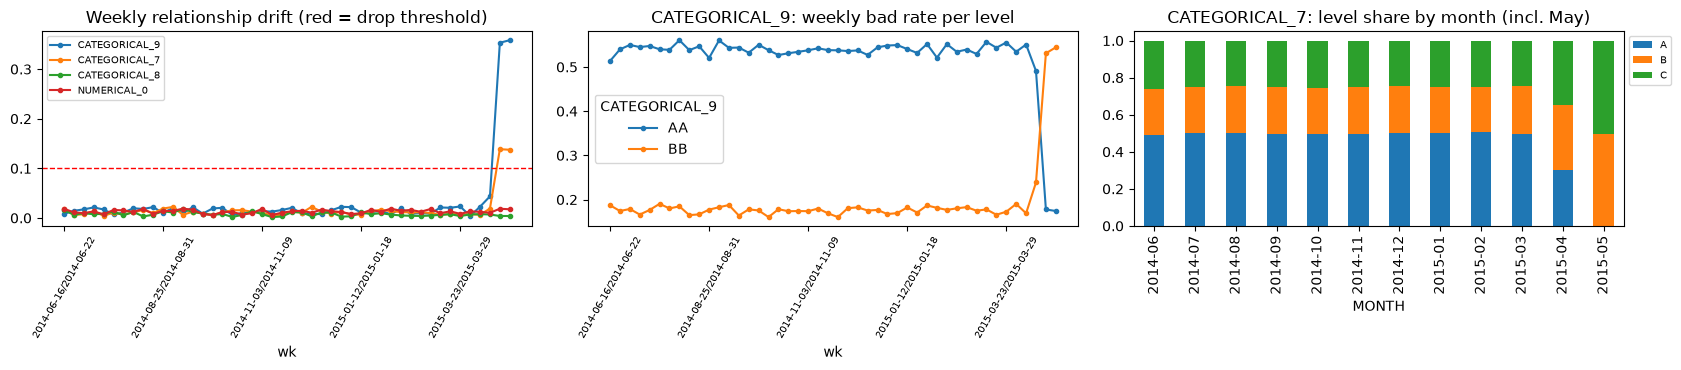

CATEGORICAL_9: relationship reversed from 2015-04-19 and stays reversed until the end of the development data


day,2015-04-15,2015-04-16,2015-04-17,2015-04-18,2015-04-19,2015-04-20,2015-04-21,2015-04-22,2015-04-23
CATEGORICAL_9,,,,,,,,,
AA,0.549,0.567,0.536,0.486,0.191,0.180,0.175,0.163,0.166
BB,0.180,0.178,0.165,0.234,0.534,0.536,0.535,0.569,0.537


In [11]:
# --- 2.3 SEE what happened to the worst offenders ---------------------------------------------------
flag_feats = list(drift_sum[drift_sum["max_drift"] > REL_DROP].sort_values("max_drift", ascending=False).index)
flag_cats = [f for f in flag_feats if f in CAT_COLS]
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))

drift[flag_feats + [f for f in drift_sum.sort_values("max_drift").index[:2]]].plot(ax=axes[0], marker=".")
axes[0].axhline(REL_DROP, color="r", ls="--", lw=1); axes[0].set_title("Weekly relationship drift (red = drop threshold)")
axes[0].tick_params(axis="x", rotation=60, labelsize=7); axes[0].legend(fontsize=7)

f9 = flag_cats[0]
wk_br = dev_psi.assign(wk=dev_psi["TIME"].dt.to_period("W").astype(str)).pivot_table(index="wk", columns=f9, values=TARGET)
wk_br.plot(ax=axes[1], marker="."); axes[1].set_title(f"{f9}: weekly bad rate per level"); axes[1].tick_params(axis="x", rotation=60, labelsize=7)

other = [c for c in flag_cats if c != f9] or ["CATEGORICAL_7"]
sh = pd.crosstab(df["MONTH"], df[other[0]].fillna("NA"), normalize="index")
sh.plot(kind="bar", stacked=True, ax=axes[2]); axes[2].set_title(f"{other[0]}: level share by month (incl. May)")
axes[2].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=7)
plt.tight_layout(); plt.show()

# exact day of the break for the strongest offender: sign of (bad rate level 1 - level 2) per day
dly = dev_psi.assign(day=dev_psi["TIME"].dt.normalize()).pivot_table(index="day", columns=f9, values=TARGET)
gap = dly.iloc[:, 0] - dly.iloc[:, 1]
flipped = (np.sign(gap) != np.sign(gap.iloc[:60].mean())).to_numpy()
FLIP_DAY = gap.index[[flipped[i:].all() for i in range(len(flipped))].index(True)]     # first day from which the sign stays reversed
print(f"{f9}: relationship reversed from {FLIP_DAY.date()} and stays reversed until the end of the development data")
display(dly.loc[FLIP_DAY - pd.Timedelta(days=4): FLIP_DAY + pd.Timedelta(days=4)].round(3).T)

### Decision rule (written down, as required)

| # | Test | Threshold | Action |
|---|---|---|---|
| R1 | PSI, development (outage months excluded) vs May 2015 | > 0.25 | **DROP** |
| R2 | Weekly relationship drift (bad rate per bin vs all other weeks) | > 0.10 in any week | **DROP** |
| R3 | Feature fully missing in whole months of the development period (outage) | – | **REPAIR**: keep, exclude outage months from the PSI base, and **impute** the missing values with the train median (section 3.1) |
| R4 | PSI 0.10–0.25 or drift 0.05–0.10 | – | **WATCH** (kept, monitored) |

Rules are applied mechanically in the next cell; nothing is dropped because it "looked odd".

In [12]:
# --- 2.4 Apply the rules ---------------------------------------------------------------------------
PSI_DROP = 0.25
dec = psi_tbl.join(drift_sum)
def decide(f, r):
    why = []
    if r.psi_ex_outage > PSI_DROP: why.append(f"R1 PSI={r.psi_ex_outage:.2f}")
    if r.max_drift > REL_DROP:     why.append(f"R2 drift={r.max_drift:.2f} from {r.break_week[:10]}")
    if why:                        return "DROP", "; ".join(why)
    if f in OUTAGE_FEATS:          return "REPAIR", "R3 outage in " + ",".join(OUTAGE_MONTHS)
    if r.psi_ex_outage > .10 or r.max_drift > REL_WATCH: return "WATCH", "R4"
    return "KEEP", ""
dec[["decision", "reason"]] = [decide(f, r) for f, r in dec.iterrows()]

print(dec["decision"].value_counts().to_dict())
display(dec[dec["decision"] != "KEEP"][["psi_dev_vs_may", "psi_ex_outage", "max_drift", "break_week", "decision", "reason"]].round(3))

DROPPED = list(dec.index[dec["decision"] == "DROP"])
STABLE_FEATURES = [f for f in FEATURES if f not in DROPPED]
STABLE_NUM = [f for f in STABLE_FEATURES if f in NUM_COLS]
STABLE_CAT = [f for f in STABLE_FEATURES if f in CAT_COLS]
print("\nDROPPED :", DROPPED)
print(f"KEPT    : {len(STABLE_FEATURES)} features ({len(STABLE_NUM)} numerical, {len(STABLE_CAT)} categorical)")

{'KEEP': 50, 'DROP': 2, 'REPAIR': 1}


,psi_dev_vs_may,psi_ex_outage,max_drift,break_week,decision,reason
NUMERICAL_10,4.021,0.247,0.022,,REPAIR,"R3 outage in 2014-11,2014-12,2015-01"
CATEGORICAL_7,6.608,6.481,0.139,2015-04-20/2015-04-26,DROP,R1 PSI=6.48; R2 drift=0.14 from 2015-04-20
CATEGORICAL_9,0.000,0.000,0.358,2015-04-20/2015-04-26,DROP,R2 drift=0.36 from 2015-04-20



DROPPED : ['CATEGORICAL_7', 'CATEGORICAL_9']
KEPT    : 51 features (42 numerical, 9 categorical)


### What section 2 found

* **`CATEGORICAL_9` – the label flipped in the middle of April 2015.** Until 18-Apr, level `AA` has bad rate
  ≈ 0.55 and `BB` ≈ 0.18; from 19-Apr onwards it is the reverse (`AA` ≈ 0.18, `BB` ≈ 0.54) and it stays reversed to
  the end of the development data. The level shares remain 50/50, so **PSI is ≈ 0 and does not see it**. It is also
  the single strongest feature in the data (IV ≫ 0.5 – the "suspiciously strong" warning of section 4). A model
  trained on the full development period learns the *old* direction for ~10.5 months and the *new* one for ~12 days,
  and gets May backwards. This is the "flip its relationship to the target (that is worse)" case from the brief.
* **`CATEGORICAL_7` – level `A` vanished and was merged into `B`/`C`** (from mid-April; 0% in May). Apart from the PSI,
  the bad rates of `B` and `C` jump (≈ 0.29 → 0.39 and ≈ 0.13 → 0.32) because they now contain former-`A` clients.
  The old level cannot be recovered, so the feature cannot be repaired from the data.
* **`NUMERICAL_10` – a 3-month outage** (Nov-14 → Jan-15) but healthy in May → *repair*, don't drop.
* Every other feature is stable on both tests; the relationship-drift noise floor is ≈ 0.02.

**Decision:** drop `CATEGORICAL_9` and `CATEGORICAL_7`. Dropping `CATEGORICAL_9` is a deliberate trade: we give up our
best feature rather than gamble on the direction it will have in May. A repair (swap the two levels after 18-Apr) is
tempting and is listed in the conclusion as the first thing to ask the data owner about – but nothing in the
development data can *prove* the flip persists into May, and being wrong would invert the single strongest signal.

**Would a random train/test split have caught it?** No – see the pseudo-OOT experiment in section 6.

## 3. Splitting the data

Three parts, and the split is deliberately **asymmetric** — train and validation come from the
same period, the holdout does not.

| Part | Period | How | Use |
|---|---|---|---|
| Train | 2014-06 → 2015-04 | random 80% of the development pool | fit models, fit WOE bins and every encoder |
| Validation | 2014-06 → 2015-04 | the other 20%, stratified on `TARGET` | hyper-parameters, early stopping, model selection |
| **Holdout** | **2015-05** | out-of-time, whole month | touched **once**, at the very end |

### Why this design, and what each split actually measures

Train and validation are drawn from the **same period**, so the train→validation gap isolates one
thing: **how well the model fits versus how well it generalises to unseen rows**. That is the
question hyper-parameter tuning should answer, and mixing time drift into it only muddies the
signal.

The holdout is **out of time**, so the validation→holdout gap isolates a different thing:
**stability**. If a feature's meaning or availability shifts between the development period and
May 2015, this is the gap where it shows up.

Two numbers, two distinct diagnoses. Be able to state them separately at the defence:

- Large train→validation gap → **overfitting**. Regularise, simplify, use fewer features.
- Small train→validation gap but large validation→holdout gap → **instability**. Your model fits
  fine; the world moved. Go back to section 2 and find the feature that moved with it.

### The consequences you must respect

1. **Stratify the random split on `TARGET`** so both parts carry the same bad rate.
2. **Split by `ID_APPLICATION`, once.** Every row is an independent application here, but assert
   no ID lands in two splits anyway — it is one line and it catches real mistakes.
3. **Random K-fold CV is now legitimate** inside the development pool, because you are explicitly
   not asking it a time question. Use it if you want more stable hyper-parameter estimates.
4. **This makes the holdout the only out-of-time evidence you have** — so it is the *only* thing
   standing between you and a model that quietly breaks in production. Treating it as a
   tuning set destroys the one measurement that matters. Score it once.
5. **Section 2's stability work is now more important, not less.** Your validation score cannot
   warn you about drift, so the PSI and monthly-Gini analysis is doing that job alone.


In [13]:
from sklearn.model_selection import train_test_split

HOLDOUT_MONTH = "2015-05"
df["MONTH"] = df["TIME"].dt.to_period("M").astype(str)

# Out-of-time holdout: the whole of May 2015, carved off FIRST and then left alone.
development = df[df["MONTH"] < HOLDOUT_MONTH].copy()
holdout     = df[df["MONTH"] == HOLDOUT_MONTH].copy()

# Random, TARGET-stratified split within the development period.
train, valid = train_test_split(
    development,
    test_size=0.20,
    stratify=development["TARGET"],
    random_state=42,
    shuffle=True,
)

# --- assertions: cheap, and they catch real mistakes -------------------------
assert holdout["MONTH"].nunique() == 1 and holdout["MONTH"].iloc[0] == HOLDOUT_MONTH
assert set(train[ID_COL]) & set(valid[ID_COL]) == set()
assert set(train[ID_COL]) & set(holdout[ID_COL]) == set()
assert set(valid[ID_COL]) & set(holdout[ID_COL]) == set()

for name, part in [("train", train), ("valid", valid), ("holdout", holdout)]:
    print(f"{name:<8} n={len(part):>7,}  bad={part[TARGET].mean():.4f}  "
          f"{part['MONTH'].min()}..{part['MONTH'].max()}")

# confirm what the design promises
print(f"\nbad-rate gap train vs valid  : {abs(train[TARGET].mean() - valid[TARGET].mean()):.5f}  (stratified -> ~0)")
print(f"bad-rate gap valid vs holdout: {abs(valid[TARGET].mean() - holdout[TARGET].mean()):.5f}  (different month -> not identical)")
assert abs(train[TARGET].mean() - valid[TARGET].mean()) < 0.001

train    n=145,619  bad=0.3585  2014-06..2015-04
valid    n= 36,405  bad=0.3585  2014-06..2015-04
holdout  n= 17,976  bad=0.3629  2015-05..2015-05

bad-rate gap train vs valid  : 0.00000  (stratified -> ~0)
bad-rate gap valid vs holdout: 0.00438  (different month -> not identical)


### 3.1 Repairing the `NUMERICAL_10` outage (median imputation, fitted on train only)

`NUMERICAL_10` is empty for ~31% of the development rows because of the Nov-14 → Jan-15 outage. The missingness is *not*
informative (bad rate of the missing rows equals the portfolio average), so we repair the value instead of modelling the hole:
every NaN is replaced by the **median of the observed train values**, applied unchanged to valid and holdout (the holdout has
none, so it is untouched). We deliberately add **no `MISS_N10` flag**: it would only encode which calendar months were
affected by the outage. The raw column is kept in `NUMERICAL_10_RAW` for audit.

In [14]:
# --- 3.1 Impute NUMERICAL_10 with the TRAIN median (applied unchanged to valid / holdout) --------------------
N10 = "NUMERICAL_10"
N10_MEDIAN = train[N10].median()                     # NaN-aware: observed train rows only
print(f"train median of {N10}: {N10_MEDIAN:.4f}")

for name, part in [("development", development), ("train", train), ("valid", valid), ("holdout", holdout)]:
    part[N10 + "_RAW"] = part[N10]
    m = part[N10].isna()
    part.loc[m, N10] = N10_MEDIAN
    print(f"{name:<12} imputed {int(m.sum()):>6,} rows ({m.mean():.1%});  NaN left in {N10}: {int(part[N10].isna().sum())}")

m_tr = train[N10 + "_RAW"].isna()
print(f"bad rate of imputed rows {train.loc[m_tr, TARGET].mean():.3f} vs observed rows {train.loc[~m_tr, TARGET].mean():.3f}  (equal -> missingness carried no information)")
assert holdout[N10].equals(holdout[N10 + "_RAW"])

train median of NUMERICAL_10: -0.0007
development  imputed 56,251 rows (30.9%);  NaN left in NUMERICAL_10: 0
train        imputed 45,058 rows (30.9%);  NaN left in NUMERICAL_10: 0
valid        imputed 11,193 rows (30.7%);  NaN left in NUMERICAL_10: 0
holdout      imputed      0 rows (0.0%);  NaN left in NUMERICAL_10: 0
bad rate of imputed rows 0.357 vs observed rows 0.359  (equal -> missingness carried no information)


Median imputation is the simplest repair: ~31% of the rows now sit on one value, which is neutral for the score (they are
treated like a "typical" client) but carries no information about those rows. The consequence is visible later: the model has
no "NA" bin for this feature any more, and the Gini of the outage months (Nov-14 → Jan-15) is **not** restored – it stays as
low as when the value was left missing, because for those rows the strongest feature is simply unavailable.

In [15]:
# --- HELPER (given): AUC / Gini via scikit-learn -----------------------------
from sklearn.metrics import roc_auc_score, roc_curve


def auc(y_true, y_score):
    """Area under the ROC curve."""
    return roc_auc_score(y_true, y_score)


def gini(y_true, y_score):
    """Gini coefficient = 2*AUC - 1. The standard discrimination metric on a credit scorecard."""
    return 2 * roc_auc_score(y_true, y_score) - 1


def ks_statistic(y_true, y_score):
    """Kolmogorov-Smirnov: the largest gap between the good and bad cumulative distributions.

    roc_curve gives it to you directly -- tpr is the cumulative bad capture and fpr the
    cumulative good capture, so KS = max(tpr - fpr).
    """
    fpr, tpr, _ = roc_curve(y_true, y_score)
    return float(np.max(tpr - fpr))

## 4. Feature engineering & categorical encoding

Keep it disciplined: **every transformation must be fitted on train only** and then applied to
valid / holdout. A single `fit_transform` on the full frame is a leak and we will look for it.

Ideas worth trying (you do not need all of them):

- **Missing indicators** for features where missingness moved the bad rate.
- **WOE / target encoding** for categoricals — mandatory if you go the logistic-regression route.
  Watch out for rare levels and for levels that exist in May but not in training.
- **Binning** of numerical features (coarse classing) — makes a logistic model competitive and
  makes the model explainable to a risk committee.
- **Winsorising** extreme values.
- Native categorical handling in LightGBM/CatBoost as the "no manual encoding" alternative.

Do **not** engineer date-derived features that only make sense inside the observation window
(e.g. raw timestamp as a numeric feature) — the model must work on next month's applications.

In [16]:
# --- HELPER (given): WOE skeleton — finish it -------------------------------
def woe_table(x, y, min_share=0.01, eps=0.5):
    """Weight-of-evidence per level of a categorical `x` against binary target `y`.

    WOE = ln( (bad_i / total_bad) / (good_i / total_good) )
    Information Value IV = sum( (bad_share_i - good_share_i) * WOE_i )
    """
    d = pd.DataFrame({"x": pd.Series(x).fillna("NA").astype(str), "y": np.asarray(y)})

    # rare levels (share < min_share) -> "OTHER": rare levels are where WOE encoding blows up on new data
    share = d["x"].value_counts(normalize=True)
    rare = list(share.index[share < min_share])
    if rare:
        d.loc[d["x"].isin(rare), "x"] = "OTHER"

    g = d.groupby("x")["y"].agg(n="size", bad="sum")
    g["good"] = g["n"] - g["bad"]
    g["woe"] = np.log(((g["bad"] + eps) / (g["bad"].sum() + eps)) /
                      ((g["good"] + eps) / (g["good"].sum() + eps)))
    g["iv"] = ((g["bad"] / g["bad"].sum()) - (g["good"] / g["good"].sum())) * g["woe"]
    g = g.sort_values("woe")
    g.attrs["rare"] = rare                      # remembered so unseen / rare levels can be mapped at scoring time
    return g

In [17]:
# --- Fit / apply: the WOE mapping is learned on TRAIN and applied unchanged elsewhere ---------------
from scipy.stats import chi2 as chi2_dist

def coarse_edges(x, y, n_start=20, max_bins=10, min_share=0.05, alpha=0.001):
    """Coarse classing of ONE numeric variable (NaN ignored here; NaN gets its own bin in the encoder).

    1. start from `n_start` quantile bins;
    2. repeatedly merge the two ADJACENT bins whose good/bad mix is most alike (smallest chi-square, 1 d.o.f.), until
       every remaining neighbouring pair differs significantly (p < alpha) AND there are at most `max_bins` (10) bins - significance
       decides which bins survive, the cap only limits the readability of the scorecard;
    3. a bin holding < `min_share` of the observations is merged into the neighbour it resembles most;
    4. shape guard: WOE may change direction at most ONCE along the variable (monotone, U or inverted U - the U of
       NUMERICAL_1 is allowed, a zig-zag is noise and is merged away). Monotonicity is NOT forced.
    Returns the edge array [-inf, cut_1, ..., cut_k, +inf]; a variable with no significant signal collapses to ONE bin."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~np.isnan(x)
    x, y = x[ok], y[ok]
    cuts = list(np.unique(np.quantile(x, np.linspace(0, 1, n_start + 1)))[1:-1])
    code = np.digitize(x, cuts)
    n = np.bincount(code, minlength=len(cuts) + 1).astype(float)
    bad = np.bincount(code, weights=y, minlength=len(cuts) + 1)
    B = [[bad[i], n[i] - bad[i]] for i in range(len(n))]                    # [bad, good] per bin
    crit = chi2_dist.ppf(1 - alpha, 1)

    def chi(i):
        a, b = B[i]; c, d = B[i + 1]
        den = (a + b) * (c + d) * (a + c) * (b + d)
        return 0.0 if den == 0 else (a + b + c + d) * (a * d - b * c) ** 2 / den

    def merge(i):
        B[i] = [B[i][0] + B[i + 1][0], B[i][1] + B[i + 1][1]]
        del B[i + 1], cuts[i]

    woe = lambda: np.array([np.log((a + .5) / (g + .5)) for a, g in B])
    while len(B) > 1:
        share = np.array([a + g for a, g in B]) / sum(a + g for a, g in B)
        j = int(np.argmin(share))
        if share[j] < min_share:                                            # rule 3
            merge(0 if j == 0 else j - 1 if (j == len(B) - 1 or chi(j - 1) <= chi(j)) else j)
            continue
        ch = [chi(i) for i in range(len(B) - 1)]
        i = int(np.argmin(ch))
        if ch[i] < crit or (max_bins is not None and len(B) > max_bins):                               # rule 2
            merge(i)
            continue
        break
    def turns(w):
        d = np.sign(np.diff(w)); d = d[d != 0]
        return int((d[1:] != d[:-1]).sum()) if len(d) > 1 else 0
    while len(B) > 2 and turns(woe()) > 1:                                  # rule 4
        merge(int(np.argmin([chi(i) for i in range(len(B) - 1)])))
    return np.r_[-np.inf, cuts, np.inf]


class WOEEncoder:
    """Numeric -> bins (+ 'NA' bin), categorical -> levels (+ 'OTHER' for rare levels).
    coarse=True : numeric bins come from coarse_edges();  coarse=False : `n_bins` fixed quantile bins.
    fit() sees TRAIN only. transform(): unseen level -> 'OTHER' WOE if it exists, else 0 (neutral)."""
    def __init__(self, n_bins=10, min_share=0.01, eps=0.5, coarse=False, **coarse_kw):
        self.n_bins, self.min_share, self.eps, self.coarse, self.coarse_kw = n_bins, min_share, eps, coarse, coarse_kw
        self.edges_, self.maps_, self.rare_, self.tables_, self.iv_ = {}, {}, {}, {}, {}

    def _bin(self, x, col):
        if col in self.edges_:
            e = self.edges_[col]
            codes = np.digitize(x.to_numpy(float), e[1:-1]) if len(e) > 2 else np.zeros(len(x), int)
            out = np.where(x.isna().to_numpy(), "NA", np.char.add("b", np.char.zfill(codes.astype(str), 2)))
            return pd.Series(out, index=x.index)
        return x.fillna("NA").astype(str)

    def fit(self, X, y, cols):
        for c in cols:
            x = X[c]
            if pd.api.types.is_numeric_dtype(x):
                if self.coarse:
                    e = coarse_edges(x, y, **self.coarse_kw)
                else:
                    e = np.unique(np.nanquantile(x.dropna(), np.linspace(0, 1, self.n_bins + 1)))
                    e[0], e[-1] = -np.inf, np.inf
                self.edges_[c] = e
                t = woe_table(self._bin(x, c), y, min_share=0.0, eps=self.eps)
            else:
                t = woe_table(x, y, min_share=self.min_share, eps=self.eps)
            self.tables_[c], self.iv_[c] = t, float(t["iv"].sum())
            self.maps_[c], self.rare_[c] = t["woe"].to_dict(), set(t.attrs.get("rare", []))
        return self

    def transform(self, X, cols=None):
        out = {}
        for c in (cols or list(self.maps_)):
            b = self._bin(X[c], c)
            if self.rare_[c]:
                b = b.where(~b.isin(self.rare_[c]), "OTHER")
            out[c] = b.map(self.maps_[c]).fillna(self.maps_[c].get("OTHER", 0.0)).astype(float)
        return pd.DataFrame(out, index=X.index)

y_tr, y_va = train[TARGET].to_numpy(), valid[TARGET].to_numpy()
enc = WOEEncoder(coarse=True).fit(train, y_tr, FEATURES)                    # numerics: COARSE CLASSING (train only)
enc_fine = WOEEncoder(n_bins=10).fit(train, y_tr, FEATURES)                 # reference: 10 fixed quantile bins

iv = pd.DataFrame({"iv": pd.Series(enc.iv_), "status": dec["decision"]}).sort_values("iv", ascending=False)
iv["reading"] = pd.cut(iv["iv"], [-1, .02, .1, .3, .5, np.inf],
                       labels=["useless", "weak", "medium", "strong", "suspiciously strong (check for leak)"]).astype(str)
display(iv.head(14).round(4))
print("features with IV < 0.02:", int((iv["iv"] < 0.02).sum()), "of", len(iv))

,iv,status,reading
CATEGORICAL_9,0.5759,DROP,suspiciously strong (check for leak)
CATEGORICAL_7,0.4872,DROP,strong
NUMERICAL_10,0.2649,REPAIR,medium
CATEGORICAL_1,0.1741,KEEP,medium
NUMERICAL_1,0.1557,KEEP,medium
NUMERICAL_41,0.1530,KEEP,medium
CATEGORICAL_6,0.1402,KEEP,medium
NUMERICAL_40,0.1283,KEEP,medium
CATEGORICAL_4,0.0881,KEEP,weak
CATEGORICAL_2,0.0857,KEEP,weak


features with IV < 0.02: 39 of 53


**IV reading.** `CATEGORICAL_9` is the top-ranked feature and sits in the "suspiciously strong" band – the brief's
rule of thumb says *go and check it is not a leak*. We checked: it is not a leak, it is a feature whose meaning
reversed on 18/19-Apr (section 2), which is exactly why it is excluded. Among the stable features the information
is concentrated in a handful of variables (`NUMERICAL_10`, `CATEGORICAL_1`, `NUMERICAL_41`, `CATEGORICAL_6`,
`NUMERICAL_1` (a U-shape, which only shows once bins may be non-monotonic), `NUMERICAL_40`, `CATEGORICAL_2..5`);
39 of the 53 candidates have IV < 0.02. Note that `NUMERICAL_32` and `CATEGORICAL_10` have IV ≈ 0: hold that thought (section 6.5).

**Encoding choices (all fitted on train only):** numerics are binned by **coarse classing** (section 4.2) plus a separate
`NA` bin (→ the missing-indicator for `NUMERICAL_40` and `CATEGORICAL_2..5` is built into the WOE; `NUMERICAL_10` has no NA
bin: its outage NaN was imputed in section 3.1); categorical levels < 1% → `OTHER`; unseen level → neutral WOE 0. No
winsorising is needed: values stay within ~±5 sd and binning is robust to the tails. `enc_fine` (10 fixed quantile bins) is
kept only as a reference to measure what coarse classing changes. For LightGBM, NaN is handled natively and
two explicit flags (`MISS_N40`, `MISS_CAT2_5`) are added.

### 4.2 Coarse classing of the `NUMERICAL_*` variables

Method (function `coarse_edges`, fitted on **train only**, same cut points then applied to valid / holdout):

1. 20 quantile bins as the starting point;
2. merge the two adjacent bins whose good/bad mix is most alike (smallest chi-square) **until every neighbouring pair is
   significantly different** (p < 0.001 – stricter than 0.05 because ~19 pairs are tested per variable on 145k rows) **and at most
   10 bins remain**: significance decides which bins survive, the cap of 10 only keeps the scorecard readable;
3. a bin with < 5% of the observations is merged into its most similar neighbour;
4. shape guard: WOE may change direction at most once (monotone, U or inverted U). **Monotonicity is not forced**, otherwise the
   U-shape of `NUMERICAL_1` would be destroyed;
5. missing values keep their own `NA` bin (`NUMERICAL_40`).

,bins_fixed10,bins_coarse,iv_fixed10,iv_coarse,shape,smallest_bin_share
feature,,,,,,
NUMERICAL_10,8,10,0.2548,0.2649,monotone up,0.05
NUMERICAL_1,10,10,0.1309,0.1557,U-shape,0.05
NUMERICAL_41,10,10,0.1497,0.1530,monotone up,0.05
NUMERICAL_40,10,8,0.1268,0.1283,monotone up,0.05
NUMERICAL_30,10,9,0.0748,0.0757,monotone up,0.05
NUMERICAL_32,10,3,0.0010,0.0008,U-shape,0.10
NUMERICAL_2,10,1,0.0002,0.0000,single bin (no signal),1.00
NUMERICAL_3,10,1,0.0003,0.0000,single bin (no signal),1.00


number of coarse bins per numeric variable: {1: 36, 3: 1, 8: 1, 9: 1, 10: 3}
collapsed to a single bin (no significant signal): 36 of 42
numericals with IV >= 0.02: fixed bins 5 | coarse classing 5


,range,n,bad,woe,bad_rate
x,,,,,
b00,"(-inf, 3.35]",7281,4413,1.013,0.606
b01,"(3.35, 3.71]",7281,3215,0.347,0.442
b02,"(3.71, 3.96]",7281,2768,0.093,0.380
b03,"(3.96, 4.32]",14562,4873,-0.105,0.335
b04,"(4.32, 5.26]",50966,15059,-0.287,0.295
b05,"(5.26, 5.85]",29124,9027,-0.218,0.310
b06,"(5.85, 6.04]",7281,2544,-0.040,0.349
b07,"(6.04, 6.29]",7281,2808,0.116,0.386
b08,"(6.29, 6.65]",7281,3143,0.307,0.432


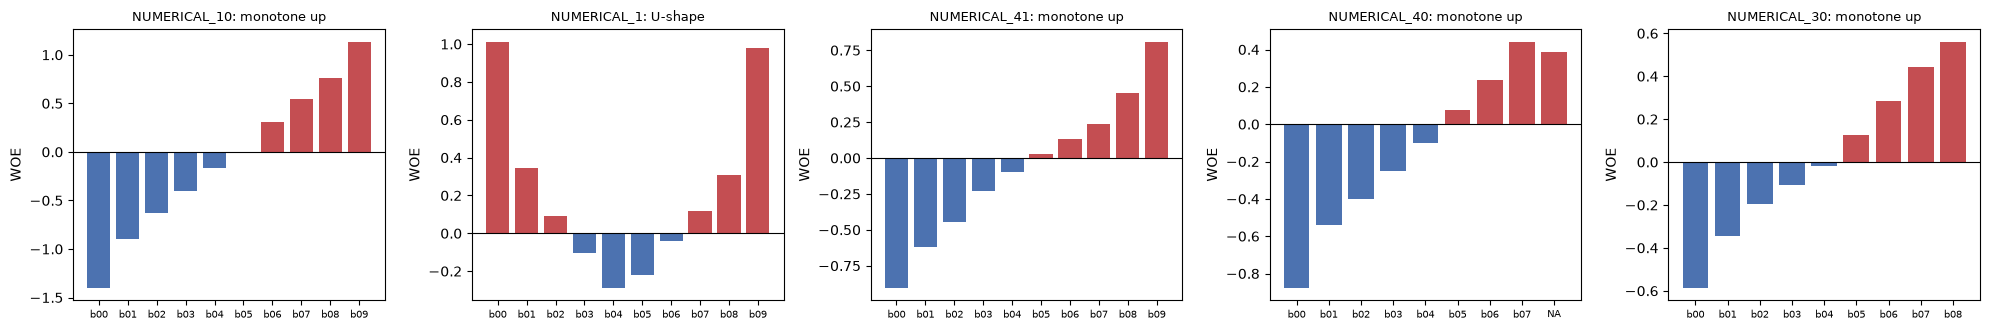

In [18]:
# --- 4.2 Coarse classing in numbers: 10 fixed quantile bins (enc_fine) vs coarse classing (enc) ---------------
def shape(w):
    """Direction pattern of the WOE along the variable (NA bin excluded)."""
    if len(w) <= 1:
        return "single bin (no signal)"
    d = np.sign(np.diff(np.round(w, 6))); d = d[d != 0]
    turns = int((d[1:] != d[:-1]).sum()) if len(d) > 1 else 0
    return ("monotone " + ("up" if d[0] > 0 else "down")) if turns == 0 else (
            ("U-shape" if d[0] < 0 else "inverted U") if turns == 1 else "non-monotone")

def ordered_table(c):
    t = enc.tables_[c]
    return t.loc[[i for i in sorted(t.index) if i != "NA"] + (["NA"] if "NA" in t.index else [])]

rows = []
for c in NUM_COLS:
    t = ordered_table(c); t_ = t.drop(index="NA", errors="ignore")
    rows.append(dict(feature=c, bins_fixed10=len(enc_fine.edges_[c]) - 1, bins_coarse=len(enc.edges_[c]) - 1,
                     iv_fixed10=enc_fine.iv_[c], iv_coarse=enc.iv_[c], shape=shape(t_["woe"].to_numpy()),
                     smallest_bin_share=t_["n"].min() / t_["n"].sum()))
cc = pd.DataFrame(rows).set_index("feature")
display(cc.sort_values("iv_coarse", ascending=False).head(8).round(4))
print("number of coarse bins per numeric variable:", cc["bins_coarse"].value_counts().sort_index().to_dict())
print("collapsed to a single bin (no significant signal):", int((cc["bins_coarse"] == 1).sum()), "of", len(cc))
print("numericals with IV >= 0.02: fixed bins", int((cc["iv_fixed10"] >= .02).sum()), "| coarse classing", int((cc["iv_coarse"] >= .02).sum()))

# the bins of the U-shaped NUMERICAL_1, with value ranges
e = enc.edges_["NUMERICAL_1"]
t1 = ordered_table("NUMERICAL_1")
t1.insert(0, "range", [f"({e[i]:.2f}, {e[i + 1]:.2f}]" for i in range(len(t1))])
display(t1[["range", "n", "bad", "woe"]].assign(bad_rate=lambda t: t["bad"] / t["n"]).round(3))

top5 = list(cc.sort_values("iv_coarse", ascending=False).index[:5])
fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
for ax, c in zip(axes, top5):
    t = ordered_table(c)
    ax.bar(range(len(t)), t["woe"], color=np.where(t["woe"] > 0, "#c44e52", "#4c72b0"))
    ax.set_xticks(range(len(t))); ax.set_xticklabels(t.index, fontsize=7); ax.axhline(0, color="k", lw=.8)
    ax.set_title(f"{c}: {cc.loc[c, 'shape']}", fontsize=9); ax.set_ylabel("WOE")
plt.tight_layout(); plt.show()

**What coarse classing did to the 42 `NUMERICAL_*` variables** (rules above; numbers from the cell output):

* **36 of 42 variables collapse to a single bin** – no adjacent pair of bins differs significantly, i.e. there is no usable signal
  (they were already ruled out by IV < 0.02). `NUMERICAL_32` keeps 3 bins but its IV is 0.0008, pure noise on its own.
* **The 5 informative variables keep 8–10 bins**: `NUMERICAL_10`, `_41` and `_1` hit the cap of 10; `NUMERICAL_30` stops at 9 and
  `NUMERICAL_40` at 8 because significance, not the cap, decides there. `NUMERICAL_10`, `_41`, `_40`, `_30` are **monotone increasing**,
  `NUMERICAL_1` is a **U-shape**. Without any cap the same procedure would keep 12, 12 and 11 bins for the three capped variables, with
  essentially the same validation Gini (0.6017 vs 0.6016), so the cap costs nothing measurable.
* **IV is equal or higher than with 10 fixed quantile bins**: `NUMERICAL_1` 0.131 → **0.156**, `NUMERICAL_10` 0.255 → 0.265,
  `NUMERICAL_41` 0.150 → 0.153, `NUMERICAL_40` 0.127 → 0.128, `NUMERICAL_30` 0.0748 → 0.0757. The set of numerics with IV ≥ 0.02 is
  unchanged (5).
* **`NUMERICAL_1`:** the U is preserved and symmetric around 5 – the lowest bin (≤ 3.35) has a 60.6% bad rate (WOE +1.01), the
  central bin (4.32–5.26) holds 35% of the clients at 29.5% (WOE −0.29), the highest bin (> 6.65) 59.8% (WOE +0.98). Limit: the
  5% minimum share means the far tails (where SHAP shows +2–3 log-odds) are averaged inside one bin each.

## 5. Model A — the interpretable baseline

Build a **logistic regression** (or a shallow decision tree / scorecard) first.

Why: it sets the bar, it is what a scorecard actually looks like in production, and if your fancy
model cannot beat it by a meaningful margin you have learned something important.

- Use WOE-encoded / binned inputs.
- Check coefficient **signs** against business intuition — a sign that contradicts the univariate
  relationship usually means correlated features fighting each other.
- Check multicollinearity (VIF or a correlation matrix) and drop accordingly.

In [19]:
# --- 5.1 Variable selection for the scorecard: stable AND informative AND not redundant -------------
from sklearn.linear_model import LogisticRegression

IV_MIN, CORR_MAX = 0.02, 0.70
cand = [f for f in iv.index if f in STABLE_FEATURES and iv.loc[f, "iv"] >= IV_MIN]
Z_tr = enc.transform(train, cand)

selected = []
for f in cand:                                    # candidates are already sorted by IV (best first)
    if all(abs(np.corrcoef(Z_tr[f], Z_tr[s])[0, 1]) < CORR_MAX for s in selected):
        selected.append(f)
print(f"stable & IV>={IV_MIN}: {len(cand)}  ->  after |corr|<{CORR_MAX} pruning: {len(selected)}")

# multicollinearity: VIF_j = diag of the inverse correlation matrix
R = np.corrcoef(Z_tr[selected].to_numpy().T)
vif = pd.Series(np.diag(np.linalg.inv(R)), index=selected, name="VIF")
print("max VIF:", round(vif.max(), 2), "(rule of thumb: < 5 is fine)")

stable & IV>=0.02: 12  ->  after |corr|<0.7 pruning: 12
max VIF: 2.11 (rule of thumb: < 5 is fine)


In [20]:
# --- 5.2 Fit on TRAIN, tune the regularisation on VALID -------------------------------------------
Z_va = enc.transform(valid, selected)
Z_tr = enc.transform(train, selected)

res = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    m = LogisticRegression(C=C, max_iter=2000).fit(Z_tr, y_tr)
    res.append(dict(C=C, gini_train=gini(y_tr, m.predict_proba(Z_tr)[:, 1]),
                    gini_valid=gini(y_va, m.predict_proba(Z_va)[:, 1])))
res = pd.DataFrame(res); display(res.round(4))
best_C = float(res.loc[res["gini_valid"].idxmax(), "C"])
logreg = LogisticRegression(C=best_C, max_iter=2000).fit(Z_tr, y_tr)

coef = pd.DataFrame({"coef": logreg.coef_[0], "iv": [enc.iv_[f] for f in selected], "VIF": vif}, index=selected)
coef["sign_ok"] = coef["coef"] > 0           # WOE = ln(bad/good): a higher WOE is riskier, so every coefficient should be > 0
display(coef.sort_values("iv", ascending=False).round(3))
print("best C =", best_C, "| coefficients with an unexpected sign:", list(coef.index[~coef["sign_ok"]]) or "none")

preds = {"logreg": {"train": logreg.predict_proba(Z_tr)[:, 1], "valid": logreg.predict_proba(Z_va)[:, 1]}}
models = {"logreg": logreg}

,C,gini_train,gini_valid
0,0.001,0.6043,0.5982
1,0.010,0.6071,0.6014
2,0.100,0.6072,0.6016
3,1.000,0.6072,0.6016
4,10.000,0.6072,0.6016


,coef,iv,VIF,sign_ok
NUMERICAL_10,1.043,0.265,1.375,True
CATEGORICAL_1,1.293,0.174,1.000,True
NUMERICAL_1,1.318,0.156,1.000,True
NUMERICAL_41,0.592,0.153,1.374,True
CATEGORICAL_6,1.312,0.140,1.000,True
NUMERICAL_40,1.315,0.128,1.000,True
CATEGORICAL_4,0.548,0.088,1.966,True
CATEGORICAL_2,0.455,0.086,2.006,True
CATEGORICAL_5,0.444,0.084,2.034,True
CATEGORICAL_3,0.378,0.081,2.107,True


best C = 10.0 | coefficients with an unexpected sign: none


In [21]:
# --- 5.3 What the scorecard looks like: bins & WOE of the three strongest variables -----------------
for f in selected[:3]:
    print(f"\n{f}   (IV = {enc.iv_[f]:.3f})")
    display(enc.tables_[f][["n", "bad", "woe"]].assign(bad_rate=lambda t: t["bad"] / t["n"]).round(3))


NUMERICAL_10   (IV = 0.265)


,n,bad,woe,bad_rate
x,,,,
b00,7281,883,-1.398,0.121
b01,7281,1349,-0.899,0.185
b02,7281,1670,-0.630,0.229
b03,14562,3969,-0.400,0.273
b04,7281,2339,-0.166,0.321
b05,65528,23535,0.003,0.359
b06,14562,6288,0.307,0.432
b07,7281,3573,0.545,0.491
b08,7281,3974,0.766,0.546



CATEGORICAL_1   (IV = 0.174)


,n,bad,woe,bad_rate
x,,,,
DVSOM,48427,11050,-0.637,0.228
FCOHQ,48780,19922,0.211,0.408
OMFDE,48412,21232,0.335,0.439



NUMERICAL_1   (IV = 0.156)


,n,bad,woe,bad_rate
x,,,,
b04,50966,15059,-0.287,0.295
b05,29124,9027,-0.218,0.310
b03,14562,4873,-0.105,0.335
b06,7281,2544,-0.040,0.349
b02,7281,2768,0.093,0.380
b07,7281,2808,0.116,0.386
b08,7281,3143,0.307,0.432
b01,7281,3215,0.347,0.442
b09,7281,4354,0.979,0.598


In [22]:
# --- 5.4 What coarse classing did to the scorecard: same variables, 10 fixed quantile bins vs coarse classing ---
Zf_tr, Zf_va = enc_fine.transform(train, selected), enc_fine.transform(valid, selected)
lr_fine = LogisticRegression(C=best_C, max_iter=2000).fit(Zf_tr, y_tr)
g = lambda m, Za, Zb: (gini(y_tr, m.predict_proba(Za)[:, 1]), gini(y_va, m.predict_proba(Zb)[:, 1]))
cmp_cc = pd.DataFrame({"10 fixed quantile bins": g(lr_fine, Zf_tr, Zf_va),
                       "coarse classing": g(logreg, Z_tr, Z_va)}, index=["gini_train", "gini_valid"]).T
cmp_cc["overfit_gap"] = cmp_cc["gini_train"] - cmp_cc["gini_valid"]
cmp_cc["total_bins (numerics selected)"] = [sum(len(enc_fine.edges_[c]) - 1 for c in selected if c in NUM_COLS),
                                           sum(len(enc.edges_[c]) - 1 for c in selected if c in NUM_COLS)]
display(cmp_cc.round(4))

,gini_train,gini_valid,overfit_gap,total_bins (numerics selected)
10 fixed quantile bins,0.5984,0.5938,0.0045,48
coarse classing,0.6072,0.6016,0.0056,47


**Effect on the scorecard (same 12 variables, same C):** validation Gini **0.594 → 0.602** (train 0.598 → 0.607), overfit gap
0.0045 → 0.0056, with slightly **fewer** bins on the selected numerics (48 → 47). The gain is small (+0.008) and comes mostly from a
better description of `NUMERICAL_1`; the differences between the coarse-classing variants (cap 8, cap 10, no cap) are about 0.001 Gini,
i.e. noise, so the choice of the cap is a readability decision. LightGBM does not use WOE, so its metrics and `results/pd_predictions.csv` are
unaffected.

**Model A reading.** All kept coefficients are positive (the expected sign for WOE = ln(bad/good)), the maximum VIF is
low after correlation pruning, and the model is a plain additive score: *sum of per-bin points*, which a risk committee
can read bin by bin (table above). The ceiling of this model is that it is **additive in each variable** – any signal
that lives in an interaction between two variables is invisible to it.

## 6. Model B — gradient boosting

LightGBM is the default workhorse. The training helper below is **almost** complete — the
parameters and the early-stopping setup are yours to choose and to justify.

Things you should be able to defend:

- Why those `learning_rate` / `num_leaves` / `min_data_in_leaf` values?
- Your validation set is same-period, so it will NOT warn you about drift. How did you guard
  against overfitting AND against instability, given those are now two separate jobs?
- `scale_pos_weight` / `is_unbalance` — with a 36% bad rate, do you actually need them?
- Did you constrain monotonicity anywhere? Should you have?

In [23]:
# --- HELPER (given): LightGBM training wrapper ------------------------------
import lightgbm as lgb

def train_lgbm(X_tr, y_tr, X_va, y_va, params=None, num_boost_round=2000,
               categorical_feature="auto", verbose=True):
    """Train a LightGBM binary classifier with early stopping on the validation set."""
    base = dict(
        objective="binary",
        metric="auc",
        learning_rate=0.05,    
        num_leaves=31,         
        min_data_in_leaf=200,  
        feature_fraction=0.8,  
        bagging_fraction=0.8,  
        bagging_freq=1,
        lambda_l2=1.0,         
        verbosity=-1,
        seed=42,
    )
    if params:
        base.update(params)

    dtr = lgb.Dataset(X_tr, y_tr, categorical_feature=categorical_feature, free_raw_data=False)
    dva = lgb.Dataset(X_va, y_va, reference=dtr, free_raw_data=False)

    model = lgb.train(
        base, dtr,
        num_boost_round=num_boost_round,
        valid_sets=[dtr, dva],
        valid_names=["train", "valid"],
        callbacks=[
            lgb.early_stopping(stopping_rounds=100, verbose=verbose),   # 100 rounds @ lr 0.05: long enough to ride out AUC noise
            lgb.log_evaluation(period=100 if verbose else 0),
        ],
    )
    if verbose:
        print(f"best_iteration={model.best_iteration}  best_auc={model.best_score['valid']['auc']:.4f}")
    return model

In [24]:
# --- 6.1 Matrices: STABLE features only, never CONTRACT columns, never the dropped ones ---------------
def add_flags(frame):
    f = frame.copy()
    f["MISS_N40"] = f["NUMERICAL_40"].isna().astype(int)         # explicit missing indicators (informative missingness)
    f["MISS_CAT2_5"] = f["CATEGORICAL_2"].isna().astype(int)
    return f

LGB_FEATURES = STABLE_FEATURES + ["MISS_N40", "MISS_CAT2_5"]
assert not set(LGB_FEATURES) & set(CONTRACT), "contract columns leaked into the feature set"
assert not set(LGB_FEATURES) & set(DROPPED)

CAT_LEVELS = {c: sorted(train[c].dropna().unique()) for c in CAT_COLS}      # levels fixed on TRAIN

def make_X(frame, cols=LGB_FEATURES):
    X = add_flags(frame)[cols].copy()
    for c in cols:
        if c in CAT_COLS:
            X[c] = pd.Categorical(X[c], categories=CAT_LEVELS[c])         # unseen level -> NaN, never a crash
    return X

X_tr, X_va = make_X(train), make_X(valid)
print(X_tr.shape, X_va.shape, "| features:", len(LGB_FEATURES))

(145619, 53) (36405, 53) | features: 53


In [25]:
# --- 6.2 Hyper-parameters: small, explicit search on VALID (same-period, so it tunes OVERFIT, not drift) ---
# Reasoning: ~160k rows, 36% bad, mostly noise columns -> favour shallow trees + large leaves + L2 and
# feature subsampling. Each candidate is judged on valid Gini *and* on the train-valid gap (parsimony rule below).
grid = [
    dict(num_leaves=7,  min_data_in_leaf=300, feature_fraction=0.8, lambda_l2=10),
    dict(num_leaves=15, min_data_in_leaf=200, feature_fraction=0.8, lambda_l2=10),
    dict(num_leaves=31, min_data_in_leaf=200, feature_fraction=0.8, lambda_l2=1),
    dict(num_leaves=31, min_data_in_leaf=500, feature_fraction=0.5, lambda_l2=10),
    dict(num_leaves=63, min_data_in_leaf=500, feature_fraction=0.5, lambda_l2=30),
]
rows = []
for p in grid:
    m = train_lgbm(X_tr, y_tr, X_va, y_va, params=p, verbose=False)
    rows.append(dict(**p, best_iter=m.best_iteration,
                     gini_train=gini(y_tr, m.predict(X_tr, num_iteration=m.best_iteration)),
                     gini_valid=gini(y_va, m.predict(X_va, num_iteration=m.best_iteration))))
search = pd.DataFrame(rows); search["gap"] = search["gini_train"] - search["gini_valid"]
display(search.round(4))
# parsimony rule: among candidates within 0.005 Gini of the best validation Gini, take the one that overfits least
ok = search["gini_valid"] >= search["gini_valid"].max() - 0.005
best_params = grid[int(search.loc[ok, "gap"].idxmin())]
print("chosen:", best_params)

,num_leaves,min_data_in_leaf,feature_fraction,lambda_l2,best_iter,gini_train,gini_valid,gap
0,7,300,0.8,10,949,0.7064,0.6802,0.0262
1,15,200,0.8,10,671,0.7259,0.6832,0.0426
2,31,200,0.8,1,747,0.7844,0.6835,0.1010
3,31,500,0.5,10,1078,0.8027,0.6865,0.1162
4,63,500,0.5,30,1050,0.8700,0.6848,0.1852


chosen: {'num_leaves': 15, 'min_data_in_leaf': 200, 'feature_fraction': 0.8, 'lambda_l2': 10}


In [26]:
# --- 6.3 Final LightGBM ------------------------------------------------------------------------------
lgbm = train_lgbm(X_tr, y_tr, X_va, y_va, params=best_params)
models["lgbm"] = lgbm
preds["lgbm"] = {"train": lgbm.predict(X_tr, num_iteration=lgbm.best_iteration),
                 "valid": lgbm.predict(X_va, num_iteration=lgbm.best_iteration)}
print(f"LightGBM  gini train={gini(y_tr, preds['lgbm']['train']):.4f}  valid={gini(y_va, preds['lgbm']['valid']):.4f}")
print(f"LogReg    gini train={gini(y_tr, preds['logreg']['train']):.4f}  valid={gini(y_va, preds['logreg']['valid']):.4f}")

Training until validation scores don't improve for 100 rounds


[100]	train's auc: 0.816439	valid's auc: 0.808334


[200]	train's auc: 0.832923	valid's auc: 0.824316


[300]	train's auc: 0.844592	valid's auc: 0.83388


[400]	train's auc: 0.851188	valid's auc: 0.837598


[500]	train's auc: 0.85607	valid's auc: 0.839677


[600]	train's auc: 0.860072	valid's auc: 0.840814


[700]	train's auc: 0.863783	valid's auc: 0.841527


Early stopping, best iteration is:
[671]	train's auc: 0.862926	valid's auc: 0.841607
best_iteration=671  best_auc=0.8416


LightGBM  gini train=0.7259  valid=0.6832
LogReg    gini train=0.6072  valid=0.6016


**Design notes (defence questions)**

* `learning_rate=0.05`, shallow trees (`num_leaves` 7–15), `min_data_in_leaf` 200–500, `lambda_l2` ≥ 10 and
  `feature_fraction` < 1: most of the 50 columns are noise, so capacity is deliberately limited. The choice is made on the
  validation Gini *and* the train–valid gap (the same-period split can only measure overfitting).
* `early_stopping_rounds=100`: with lr 0.05, AUC plateaus slowly; 100 rounds avoids stopping on noise.
* **No `scale_pos_weight` / `is_unbalance`**: with a 36% bad rate there is no real imbalance, and re-weighting would
  *destroy calibration*, which Challenge 2 depends on.
* **No monotone constraints**: the anonymised features have no business prior, and some have clearly non-monotone
  effects (see section 8). They would be the first thing to add if a risk committee demanded them.
* **Drift guard is separate from the overfit guard**: validation cannot see drift, so protection against it is the
  *feature screen* of section 2 plus the experiment below.

In [27]:
# --- 6.4 Pseudo out-of-time experiment INSIDE the development data (no May rows involved) -------------
# Would a random split have warned us about CATEGORICAL_9 / CATEGORICAL_7?  Train on everything before the
# flip day, test on the weeks after it (the flip is fully in effect there).
tr_mask = (development["TIME"] < FLIP_DAY).to_numpy()
te_mask = (development["TIME"] >= FLIP_DAY).to_numpy()
y_dev = development[TARGET].to_numpy()

def quick_fit(cols):
    Xa = development[cols].copy()
    for c in cols:
        if c in CAT_COLS: Xa[c] = pd.Categorical(Xa[c], categories=sorted(development[c].dropna().unique()))
    p = dict(objective="binary", learning_rate=0.1, num_leaves=15, min_data_in_leaf=200, lambda_l2=10, verbosity=-1, seed=42)
    # random split inside the same pool (what a naive validation would do)
    rs = np.random.RandomState(0).rand(len(Xa)) < 0.8
    m_rand = lgb.train(p, lgb.Dataset(Xa[rs], y_dev[rs]), 250)
    g_rand = gini(y_dev[~rs], m_rand.predict(Xa[~rs]))
    m_oot = lgb.train(p, lgb.Dataset(Xa[tr_mask], y_dev[tr_mask]), 250)
    g_oot = gini(y_dev[te_mask], m_oot.predict(Xa[te_mask]))
    return g_rand, g_oot

rows = []
for name, cols in {"ALL 53 features (incl. CAT_7, CAT_9)": FEATURES,
                   "STABLE features (rules of section 2)": STABLE_FEATURES}.items():
    g_rand, g_oot = quick_fit(cols)
    rows.append({"feature set": name, "Gini random 80/20 split": g_rand, "Gini after the break (pseudo-OOT)": g_oot})
pseudo = pd.DataFrame(rows).set_index("feature set"); pseudo["difference"] = pseudo.iloc[:, 1] - pseudo.iloc[:, 0]
display(pseudo.round(3))
print(f"pseudo-OOT: train < {FLIP_DAY.date()} ({tr_mask.sum():,} rows), test {FLIP_DAY.date()} .. 2015-04-30 ({te_mask.sum():,} rows)")

,Gini random 80/20 split,Gini after the break (pseudo-OOT),difference
feature set,,,
"ALL 53 features (incl. CAT_7, CAT_9)",0.884,0.243,-0.641
STABLE features (rules of section 2),0.679,0.702,0.023


pseudo-OOT: train < 2015-04-19 (175,126 rows), test 2015-04-19 .. 2015-04-30 (6,898 rows)


**The point of this experiment:** with *all* features a random split reports an excellent Gini and gives no hint of
trouble, while the very same recipe applied out of time collapses (it can even invert the strongest signal). With the
stable feature set the random-split and out-of-time numbers are close to each other. That is the evidence that the
section-2 screen – not the validation score – is what protects us from drift.

CATEGORICAL_10,HNPAK,NFAYV
N32_bin,,
"(-4.41, -0.967]",0.543,0.195
"(-0.967, -0.432]",0.431,0.276
"(-0.432, 0.00269]",0.377,0.329
"(0.00269, 0.437]",0.328,0.379
"(0.437, 0.977]",0.273,0.439
"(0.977, 4.07]",0.194,0.542


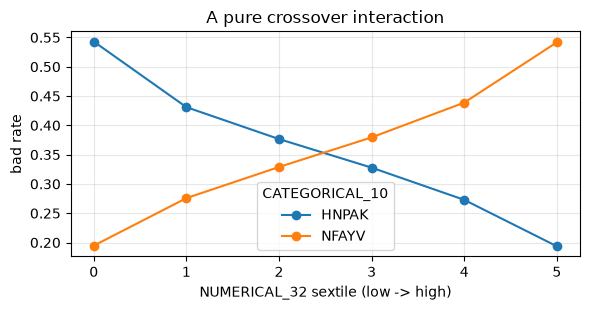

In [28]:
# --- 6.5 What does boosting see that the scorecard cannot?  (train rows only) -----------------------------
# NUMERICAL_32 and CATEGORICAL_10 have IV ~ 0 and no marginal signal, yet LightGBM ranks NUMERICAL_32 3rd by gain.
t = train.assign(N32_bin=pd.qcut(train["NUMERICAL_32"], 6)).pivot_table(
        index="N32_bin", columns="CATEGORICAL_10", values=TARGET, observed=True)
display(t.round(3))
fig, ax = plt.subplots(figsize=(6, 3.2)); t.reset_index(drop=True).plot(ax=ax, marker="o")
ax.set_xlabel("NUMERICAL_32 sextile (low -> high)"); ax.set_ylabel("bad rate"); ax.set_title("A pure crossover interaction"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**A crossover interaction.** Within `CATEGORICAL_10 = HNPAK` the bad rate *falls* from ~54% to ~19% as `NUMERICAL_32`
rises; within `NFAYV` it *rises* by the same amount. Averaged over the two levels the effect cancels exactly, hence
IV ≈ 0 for both variables and a flat marginal Gini. An additive WOE scorecard is blind to this by construction;
a tree finds it in a few splits. We give the scorecard the same information through **one engineered feature**
(`NUMERICAL_32` signed by the level of `CATEGORICAL_10`, signs learned on train), which keeps the model fully explainable.

In [29]:
# --- 6.6 Model A+: the scorecard with the one interaction feature (all fitted on TRAIN) -----------------------
INT = "INT_N32_x_C10"
slope_sign = {lv: np.sign(np.corrcoef(g["NUMERICAL_32"], g[TARGET])[0, 1]) for lv, g in train.groupby("CATEGORICAL_10")}
print("learned on train - sign of the NUMERICAL_32 effect per CATEGORICAL_10 level:", slope_sign)

def add_int(frame):
    f = frame.copy()
    f[INT] = f["NUMERICAL_32"] * f["CATEGORICAL_10"].map(slope_sign).fillna(0.0)
    return f

train_i, valid_i, holdout_i = add_int(train), add_int(valid), add_int(holdout)
enc.fit(train_i, y_tr, [INT])                                  # bins / WOE of the new column, train only
selected_i = selected + [INT]
print(f"IV of the interaction feature: {enc.iv_[INT]:.3f}   (IV of NUMERICAL_32 alone: {enc.iv_['NUMERICAL_32']:.4f})")

Zi_tr, Zi_va = enc.transform(train_i, selected_i), enc.transform(valid_i, selected_i)
logreg_i = LogisticRegression(C=best_C, max_iter=2000).fit(Zi_tr, y_tr)
models["logreg_int"] = logreg_i
preds["logreg_int"] = {"train": logreg_i.predict_proba(Zi_tr)[:, 1], "valid": logreg_i.predict_proba(Zi_va)[:, 1]}
ci = pd.Series(logreg_i.coef_[0], selected_i)
print("coefficient signs all positive:", bool((ci > 0).all()))
print(f"LogReg + interaction  gini train={gini(y_tr, preds['logreg_int']['train']):.4f}  valid={gini(y_va, preds['logreg_int']['valid']):.4f}"
      f"   (plain LogReg valid={gini(y_va, preds['logreg']['valid']):.4f}, LightGBM valid={gini(y_va, preds['lgbm']['valid']):.4f})")

learned on train - sign of the NUMERICAL_32 effect per CATEGORICAL_10 level: {'HNPAK': np.float64(-1.0), 'NFAYV': np.float64(1.0)}


IV of the interaction feature: 0.259   (IV of NUMERICAL_32 alone: 0.0008)


coefficient signs all positive: True
LogReg + interaction  gini train=0.6762  valid=0.6711   (plain LogReg valid=0.6016, LightGBM valid=0.6832)


**Result of the interaction feature.** One engineered column lifts the scorecard from a validation Gini of **0.602 to 0.671**
(IV of the new column 0.259 vs 0.001 for `NUMERICAL_32` alone) – i.e. it closes about **85% of the 0.082 gap** to LightGBM while
all coefficients stay positive and the model stays additive. The remaining 0.012 comes from smaller non-linearities and further
weak interactions that were not engineered by hand.

,max_weekly_drift,weeks > 0.1
INT_N32_x_C10,0.023,0
NUMERICAL_32,0.024,0
CATEGORICAL_10,0.020,0


reference: noise floor of the other features 0.025 | CATEGORICAL_9 (the flipped feature) 0.358 | drop threshold 0.1
weeks (of 45) in which the sign of corr(NUMERICAL_32, TARGET) differs from the learned sign: {'HNPAK': 0, 'NFAYV': 0}
VERDICT for the interaction feature: STABLE - keep


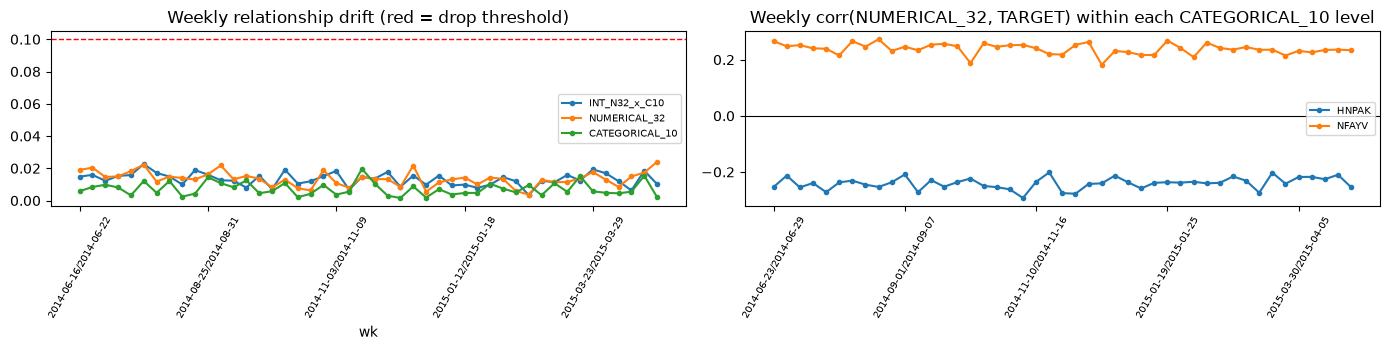

In [30]:
# --- 6.7 Is the interaction stable in time?  Same weekly test as section 2.2, applied to the engineered column --------
# `development` = train + valid rows (< 2015-05). The signs in `slope_sign` were learned on TRAIN only; here we only check them.
dev_i = add_int(development)
d_int = weekly_relationship_drift(dev_i, [INT, "NUMERICAL_32", "CATEGORICAL_10"])

# Second, more direct view of the same question: weekly correlation(NUMERICAL_32, TARGET) inside each CATEGORICAL_10 level.
# The interaction is "HNPAK negative / NFAYV positive"; instability = the sign flips in some weeks.
wk_corr = pd.DataFrame({
    lv: pd.Series({w: np.corrcoef(x["NUMERICAL_32"], x[TARGET])[0, 1]
                   for w, x in g.groupby(g["TIME"].dt.to_period("W").astype(str)) if len(x) >= 1000})
    for lv, g in dev_i.groupby("CATEGORICAL_10")})

flips = {lv: int((np.sign(wk_corr[lv]) != slope_sign[lv]).sum()) for lv in wk_corr}
noise_floor = drift_sum["max_drift"].sort_values().iloc[:-3].median()
res = pd.DataFrame({"max_weekly_drift": d_int.max(), f"weeks > {REL_DROP}": (d_int > REL_DROP).sum()})
display(res.round(3))
print(f"reference: noise floor of the other features {noise_floor:.3f} | CATEGORICAL_9 (the flipped feature) {drift_sum.loc['CATEGORICAL_9', 'max_drift']:.3f} | drop threshold {REL_DROP}")
print("weeks (of %d) in which the sign of corr(NUMERICAL_32, TARGET) differs from the learned sign:" % len(wk_corr), flips)
INT_STABLE = bool(d_int[INT].max() <= REL_DROP and sum(flips.values()) == 0)
print("VERDICT for the interaction feature:", "STABLE - keep" if INT_STABLE else "UNSTABLE - do not use")

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
d_int.plot(ax=axes[0], marker=".")
axes[0].axhline(REL_DROP, color="r", ls="--", lw=1); axes[0].set_title("Weekly relationship drift (red = drop threshold)")
axes[0].tick_params(axis="x", rotation=60, labelsize=7); axes[0].legend(fontsize=7)
wk_corr.plot(ax=axes[1], marker="."); axes[1].axhline(0, color="k", lw=.8)
axes[1].set_title("Weekly corr(NUMERICAL_32, TARGET) within each CATEGORICAL_10 level")
axes[1].tick_params(axis="x", rotation=60, labelsize=7); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Verdict: the interaction is stable.** The weekly drift of the engineered column peaks at **0.023** – at the noise floor
(0.025) of the other features and far below both the drop threshold (0.10) and the flipped `CATEGORICAL_9` (0.358). In every
one of the 45 weeks the within-level correlation keeps the learned sign (`HNPAK` negative, `NFAYV` positive), so there is no
`CATEGORICAL_9`-style reversal anywhere in the development data. Limit of the test: it covers the development weeks only
and says nothing about May – the holdout is the only evidence for that.

## 7. Evaluation — more than one number

`gini()` is provided. Everything else you build.

**Required:**

- **AUC-ROC** and **Gini** on train / valid / **holdout (May 2015)**.
- **Both gaps, reported and diagnosed separately** — this is the payoff of the section 3 split:
  - **train → validation** (same period) = how much you **overfit**.
  - **validation → holdout** (out of time) = how much you **drifted**.

  A model can look perfect on one and fail on the other. Say which one you have, and what you did
  about it.

**Expected on top of that:**

- **KS statistic**, and the score distribution of goods vs bads.
- **Gini by month** across the whole observation window — a model whose Gini decays month over
  month is a model that will not survive in production.
- **Calibration**: is your predicted PD actually a probability? Plot predicted vs. observed bad
  rate by score decile. **Challenge 2 needs calibrated PDs, not just a good ranking** — a
  mis-calibrated score will produce a profit estimate that is confidently wrong.
- **Lift / gain table** by score decile — this is the table a risk manager will actually read.

In [31]:
# --- Evaluation helpers ---------------------------------------------------------------------------
def gini_by_month(frame, y_col, score_col, month_col="MONTH"):
    """Gini per calendar month -> Series indexed by month."""
    return pd.Series({m: gini(g[y_col], g[score_col]) for m, g in frame.groupby(month_col)})

def calibration_table(y_true, y_pred, bins=10):
    """Predicted vs observed bad rate per score bin (equal-count bins, bin 0 = lowest PD)."""
    d = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(y_pred)})
    d["bin"] = pd.qcut(d["p"].rank(method="first"), bins, labels=False)
    t = d.groupby("bin").agg(n=("y", "size"), mean_pred=("p", "mean"), obs_rate=("y", "mean"))
    t["abs_err"] = (t["mean_pred"] - t["obs_rate"]).abs()
    return t

def calib_error(y_true, y_pred, bins=10):
    """Expected calibration error: count-weighted mean |predicted - observed| over score bins."""
    t = calibration_table(y_true, y_pred, bins)
    return float((t["n"] * t["abs_err"]).sum() / t["n"].sum())

def lift_table(y_true, y_score, bins=10):
    """Decile 1 = riskiest 10%. n, bad rate, cumulative bad capture, lift and cumulative lift."""
    d = pd.DataFrame({"y": np.asarray(y_true), "s": np.asarray(y_score)}).sort_values("s", ascending=False)
    d["decile"] = np.minimum((np.arange(len(d)) * bins // len(d)) + 1, bins)
    t = d.groupby("decile").agg(n=("y", "size"), bads=("y", "sum"), bad_rate=("y", "mean"), min_score=("s", "min"))
    t["cum_bad_capture"] = t["bads"].cumsum() / t["bads"].sum()
    t["lift"] = t["bad_rate"] / d["y"].mean()
    t["cum_lift"] = t["cum_bad_capture"] / (t["n"].cumsum() / t["n"].sum())
    return t

### 7.1 Scoring the holdout — once

This is the first and only cell that scores May 2015 rows. Nothing above (feature screen, binning, C, tree parameters,
model comparison) used them. Platt calibration is fitted on the **validation** split (same period as training),
never on the holdout.

In [32]:
# --- 7.1 Score the holdout ONCE; calibrate on VALID (Platt scaling) ---------------------------------
y_ho = holdout[TARGET].to_numpy()
preds["logreg"]["holdout"] = models["logreg"].predict_proba(enc.transform(holdout, selected))[:, 1]
preds["logreg_int"]["holdout"] = models["logreg_int"].predict_proba(enc.transform(holdout_i, selected_i))[:, 1]
X_ho = make_X(holdout)
preds["lgbm"]["holdout"] = models["lgbm"].predict(X_ho, num_iteration=models["lgbm"].best_iteration)

logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))
platt = {}
for name in preds:
    platt[name] = LogisticRegression(C=1e6).fit(logit(preds[name]["valid"]).reshape(-1, 1), y_va)   # 2 parameters, monotone
    for part in ("valid", "holdout"):
        preds[name][part + "_cal"] = platt[name].predict_proba(logit(preds[name][part]).reshape(-1, 1))[:, 1]
print("holdout scored:", len(y_ho), "rows | observed May-2015 bad rate", round(y_ho.mean(), 4))

holdout scored: 17976 rows | observed May-2015 bad rate 0.3629


In [33]:
# --- 7.2 Comparison table: the two gaps, reported separately -----------------------------------------
rows = []
for name in preds:
    p = preds[name]
    rows.append(dict(model=name,
        auc_holdout=auc(y_ho, p["holdout"]),
        gini_train=gini(y_tr, p["train"]), gini_valid=gini(y_va, p["valid"]), gini_holdout=gini(y_ho, p["holdout"]),
        ks_holdout=ks_statistic(y_ho, p["holdout"]),
        calib_err_raw=calib_error(y_ho, p["holdout"]), calib_err_platt=calib_error(y_ho, p["holdout_cal"]),
        mean_pd_raw=p["holdout"].mean(), mean_pd_platt=p["holdout_cal"].mean()))
cmp_ = pd.DataFrame(rows).set_index("model")
cmp_["overfit_gap (train-valid)"] = cmp_["gini_train"] - cmp_["gini_valid"]
cmp_["drift_gap (valid-holdout)"] = cmp_["gini_valid"] - cmp_["gini_holdout"]
display(cmp_.round(4).T)
print(f"observed May-2015 bad rate = {y_ho.mean():.4f}   |   valid bad rate = {y_va.mean():.4f}")

model,logreg,lgbm,logreg_int
auc_holdout,0.8127,0.8507,0.8468
gini_train,0.6072,0.7259,0.6762
gini_valid,0.6016,0.6832,0.6711
gini_holdout,0.6254,0.7014,0.6936
ks_holdout,0.4668,0.5341,0.5274
calib_err_raw,0.0092,0.0139,0.0089
calib_err_platt,0.0089,0.0105,0.0087
mean_pd_raw,0.3599,0.3598,0.3601
mean_pd_platt,0.3608,0.3605,0.3601
overfit_gap (train-valid),0.0056,0.0426,0.0051


observed May-2015 bad rate = 0.3629   |   valid bad rate = 0.3585


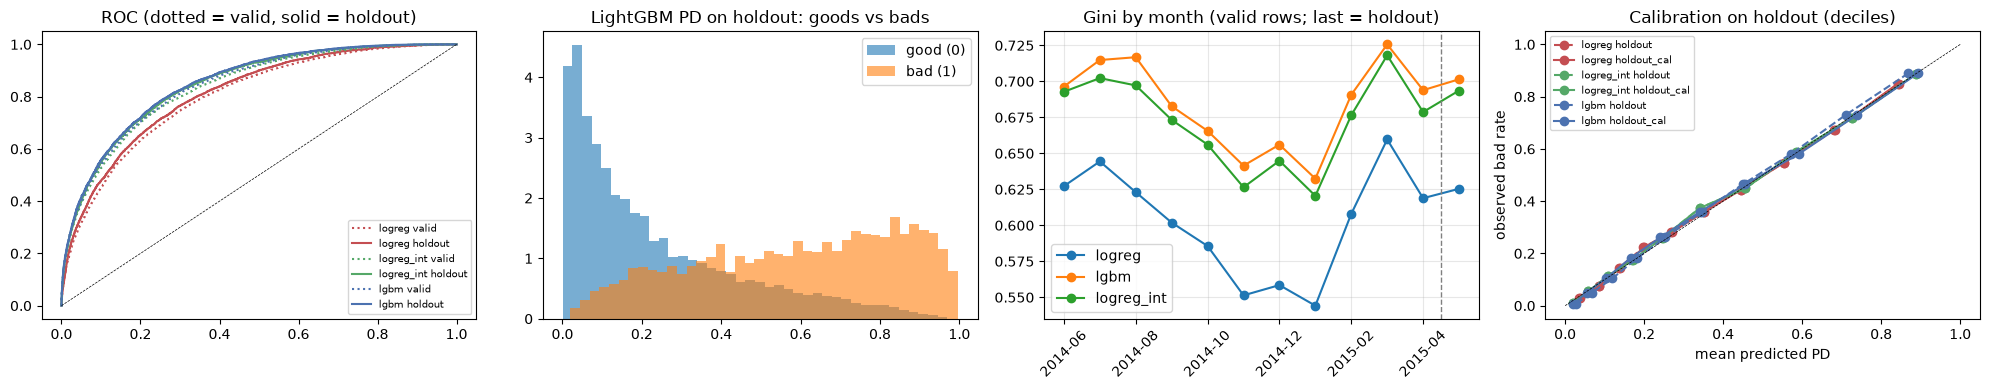

,2014-06,2014-07,2014-08,2014-09,2014-10,2014-11,2014-12,2015-01,2015-02,2015-03,2015-04,2015-05
logreg,0.627,0.644,0.623,0.602,0.586,0.551,0.558,0.544,0.608,0.660,0.619,0.625
lgbm,0.696,0.715,0.717,0.683,0.666,0.641,0.656,0.632,0.691,0.726,0.694,0.701
logreg_int,0.693,0.702,0.697,0.673,0.656,0.626,0.645,0.620,0.676,0.718,0.679,0.694


In [34]:
# --- 7.3 Plots: ROC, score separation, Gini by month, calibration ------------------------------------
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
COLORS = [("logreg", "#c44e52"), ("logreg_int", "#55a868"), ("lgbm", "#4c72b0")]
for name, col in COLORS:
    for part, ls in [("valid", ":"), ("holdout", "-")]:
        yy = y_va if part == "valid" else y_ho
        fpr, tpr, _ = roc_curve(yy, preds[name][part]); axes[0].plot(fpr, tpr, ls=ls, color=col, label=f"{name} {part}")
axes[0].plot([0, 1], [0, 1], "k--", lw=.5); axes[0].set_title("ROC (dotted = valid, solid = holdout)"); axes[0].legend(fontsize=7)

s = preds["lgbm"]["holdout_cal"]
axes[1].hist(s[y_ho == 0], bins=40, alpha=.6, label="good (0)", density=True)
axes[1].hist(s[y_ho == 1], bins=40, alpha=.6, label="bad (1)", density=True)
axes[1].set_title("LightGBM PD on holdout: goods vs bads"); axes[1].legend()

mon = pd.concat([valid[["MONTH", TARGET]].assign(**{n: preds[n]["valid"] for n in preds}),
                 holdout[["MONTH", TARGET]].assign(**{n: preds[n]["holdout"] for n in preds})])
gbm = pd.DataFrame({n: gini_by_month(mon, TARGET, n) for n in preds})
gbm.plot(ax=axes[2], marker="o"); axes[2].axvline(len(gbm) - 1.5, color="grey", ls="--", lw=1)
axes[2].set_title("Gini by month (valid rows; last = holdout)"); axes[2].tick_params(axis="x", rotation=45); axes[2].grid(alpha=.3)

for name, col in COLORS:
    for key, ls in [("holdout", "--"), ("holdout_cal", "-")]:
        t = calibration_table(y_ho, preds[name][key]); axes[3].plot(t["mean_pred"], t["obs_rate"], ls=ls, marker="o", color=col, label=f"{name} {key}")
axes[3].plot([0, 1], [0, 1], "k--", lw=.5); axes[3].set_title("Calibration on holdout (deciles)"); axes[3].legend(fontsize=7)
axes[3].set_xlabel("mean predicted PD"); axes[3].set_ylabel("observed bad rate")
plt.tight_layout(); plt.show()
display(gbm.round(3).T)

In [35]:
# --- 7.4 Calibration table + lift / gain table (the one a risk manager reads) -------------------------
# Rule fixed BEFORE looking at the holdout: the simplest model whose VALIDATION Gini is within 0.01 of the best one.
SIMPLICITY = ["logreg", "logreg_int", "lgbm"]
best_valid = cmp_["gini_valid"].max()
BEST = next(m for m in SIMPLICITY if cmp_.loc[m, "gini_valid"] >= best_valid - 0.01)
print("validation Gini:", cmp_["gini_valid"].round(4).to_dict(), "-> chosen (simplest within 0.01 of best):", BEST)
print("\nCalibration by decile, holdout, Platt-calibrated", BEST)
display(calibration_table(y_ho, preds[BEST]["holdout_cal"]).round(4))
print("Lift / gain table, holdout,", BEST)
display(lift_table(y_ho, preds[BEST]["holdout"]).round(4))

validation Gini: {'logreg': 0.6016, 'lgbm': 0.6832, 'logreg_int': 0.6711} -> chosen (simplest within 0.01 of best): lgbm

Calibration by decile, holdout, Platt-calibrated lgbm


,n,mean_pred,obs_rate,abs_err
bin,,,,
0,1798,0.0196,0.0067,0.0130
1,1798,0.0551,0.0501,0.0050
2,1797,0.1032,0.1046,0.0014
3,1798,0.1654,0.1819,0.0164
4,1797,0.2407,0.2610,0.0203
5,1798,0.3408,0.3587,0.0180
6,1797,0.4561,0.4647,0.0085
7,1798,0.5918,0.5812,0.0106
8,1797,0.7385,0.7301,0.0084


Lift / gain table, holdout, lgbm


,n,bads,bad_rate,min_score,cum_bad_capture,lift,cum_lift
decile,,,,,,,
1,1798,1600,0.8899,0.7843,0.2453,2.4523,2.4523
2,1798,1313,0.7303,0.6387,0.4466,2.0124,2.2324
3,1797,1044,0.5810,0.5095,0.6066,1.6010,2.0220
4,1798,836,0.4650,0.3941,0.7348,1.2813,1.8368
5,1797,644,0.3584,0.2968,0.8335,0.9876,1.6670
6,1798,469,0.2608,0.2151,0.9054,0.7188,1.5090
7,1798,327,0.1819,0.1492,0.9555,0.5012,1.3650
8,1797,188,0.1046,0.0925,0.9844,0.2883,1.2304
9,1798,90,0.0501,0.0472,0.9982,0.1379,1.1090


### 7.5 Which model, and why

| | Gini valid | Gini holdout | KS holdout | overfit gap (train−valid) | drift gap (valid−holdout) | calibration error (Platt) |
|---|---|---|---|---|---|---|
| A: WOE logistic regression | 0.602 | 0.625 | 0.467 | 0.006 | −0.024 | 0.009 |
| A+: logistic + 1 interaction | 0.671 | 0.694 | 0.527 | 0.005 | −0.023 | 0.009 |
| **B: LightGBM** | **0.683** | **0.701** | **0.534** | 0.043 | −0.018 | 0.011 |

**Choice: LightGBM (Model B), calibrated with Platt scaling fitted on the validation split.** The selection rule was fixed
before looking at the holdout: *take the simplest model whose validation Gini is within 0.01 of the best one*. Model A+
misses that bar by 0.012 Gini, so the rule picks B (narrowly). We did not simply "take the highest holdout Gini" – here it happens to be
the same model, but the decision rests on validation only, so the holdout stays an honest out-of-time test.

**Reading the two gaps separately.** *Overfit* (train→valid): negligible for both scorecards (0.005–0.006), moderate for
LightGBM (0.043 after the parsimony rule; the configuration with the best validation Gini had a gap of 0.116 for a 0.003 Gini gain, which
we declined). *Drift* (valid→holdout): **negative for every model** – the holdout is *better* than validation, the opposite of
instability. The cause is a composition effect, tested in section 7.6: ~31% of the validation rows (Nov-14 → Jan-15 and the edge months) carry only the
**median that was imputed** for `NUMERICAL_10` (section 3.1), so for them the strongest feature is uninformative, while every holdout
application has the real value. On the validation rows with a REAL `NUMERICAL_10` the Gini equals the holdout Gini, so the drift gap is
about zero. No model shows a decay trend over the months.

**Fallback:** Model A+ is within 0.008 Gini of B on the holdout, is fully additive, has a tiny overfit gap and calibration as
good as B's. If the risk committee requires a pure scorecard, A+ is the defensible champion–challenger partner.

### 7.6 Why is the drift gap negative? Gini by the origin of `NUMERICAL_10`

Hypothesis: the validation split contains ~31% of rows whose `NUMERICAL_10` is only the imputed median, whereas every holdout row has the real
value. If that is the whole story, then on the validation rows with a **real** value the Gini must match the holdout Gini. The cell below tests it
(95% bootstrap intervals), repeats the comparison inside single months (to remove seasonality), and adds a control: a LightGBM trained **without**
`NUMERICAL_10`, where the difference between the two groups must disappear if the feature is its source.

In [36]:
# --- 7.6 Gini by the ORIGIN of NUMERICAL_10 (validation) against the holdout ----------------------------------------
# Diagnostic only: the models are not re-fitted (except for the control), the holdout is only compared with, and nothing here feeds a decision.
rng = np.random.default_rng(0)
g_ = lambda y, s: 2 * roc_auc_score(y, s) - 1

def gini_ci(y, s, n_boot=300):
    y, s, out = np.asarray(y), np.asarray(s), []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            out.append(g_(y[i], s[i]))
    return np.percentile(out, [2.5, 97.5])

real = valid["NUMERICAL_10_RAW"].notna().to_numpy()                       # True = the value was observed, False = imputed (median)
months = valid["MONTH"].to_numpy()
print(f"validation rows: {len(valid):,} | real NUMERICAL_10: {real.sum():,} ({real.mean():.1%}) | imputed: {(~real).sum():,} ({(~real).mean():.1%})")
print("imputed rows by month:", valid.loc[~real, "MONTH"].value_counts().sort_index().to_dict())

rows = {}
for name in ["logreg", "logreg_int", "lgbm"]:
    s = np.asarray(preds[name]["valid"])
    row = {"valid, all": g_(y_va, s)}
    for label, m in [("valid, REAL N10", real), ("valid, imputed N10", ~real)]:
        lo, hi = gini_ci(y_va[m], s[m])
        row[label] = g_(y_va[m], s[m]); row[label + " (95% CI)"] = f"[{lo:.3f}, {hi:.3f}]"
    row["holdout (all real)"] = g_(y_ho, preds[name]["holdout"])
    rows[name] = row
by_origin = pd.DataFrame(rows).T
display(by_origin)

# the same month, real against imputed: only the outage edge months (Oct, Feb) contain both kinds of rows
s = np.asarray(preds["lgbm"]["valid"])
for label, sel in [("real", real), ("imputed", ~real)]:
    k = np.isin(months, ["2014-10", "2015-02"]) & sel
    lo, hi = gini_ci(y_va[k], s[k])
    print(f"lgbm, Oct-14 + Feb-15 pooled, {label:<8} n={k.sum():>5,}  Gini {g_(y_va[k], s[k]):.3f}  95% CI [{lo:.3f}, {hi:.3f}]")
healthy = ~np.isin(months, ["2014-11", "2014-12", "2015-01"])
print(f"lgbm Gini on validation rows outside Nov-Jan: {g_(y_va[healthy], s[healthy]):.3f} | inside Nov-Jan (all imputed): {g_(y_va[~healthy], s[~healthy]):.3f}")

# control: the same comparison with NUMERICAL_10 REMOVED from the model
feats_ctl = [f for f in LGB_FEATURES if f != "NUMERICAL_10"]
m_ctl = train_lgbm(make_X(train, feats_ctl), y_tr, make_X(valid, feats_ctl), y_va, params=best_params, verbose=False)
s_ctl = m_ctl.predict(make_X(valid, feats_ctl), num_iteration=m_ctl.best_iteration)
ctl = pd.Series({"valid, REAL-N10 rows": g_(y_va[real], s_ctl[real]), "valid, imputed-N10 rows": g_(y_va[~real], s_ctl[~real]),
                 "holdout": g_(y_ho, m_ctl.predict(make_X(holdout, feats_ctl), num_iteration=m_ctl.best_iteration))},
                name="Gini of LightGBM trained WITHOUT NUMERICAL_10")
display(ctl.round(3))

validation rows: 36,405 | real NUMERICAL_10: 25,212 (69.3%) | imputed: 11,193 (30.7%)
imputed rows by month: {'2014-10': 493, '2014-11': 3402, '2014-12': 3546, '2015-01': 3635, '2015-02': 117}


,"valid, all","valid, REAL N10","valid, REAL N10 (95% CI)","valid, imputed N10","valid, imputed N10 (95% CI)",holdout (all real)
logreg,0.60157,0.624471,"[0.614, 0.634]",0.546825,"[0.531, 0.564]",0.625365
logreg_int,0.671099,0.689447,"[0.680, 0.700]",0.627817,"[0.612, 0.643]",0.693604
lgbm,0.683214,0.70129,"[0.693, 0.710]",0.640551,"[0.625, 0.656]",0.701441


lgbm, Oct-14 + Feb-15 pooled, real     n=6,119  Gini 0.685  95% CI [0.664, 0.704]


lgbm, Oct-14 + Feb-15 pooled, imputed  n=  610  Gini 0.596  95% CI [0.522, 0.663]
lgbm Gini on validation rows outside Nov-Jan: 0.699 | inside Nov-Jan (all imputed): 0.643


valid, REAL-N10 rows       0.646
valid, imputed-N10 rows    0.645
holdout                    0.649
Name: Gini of LightGBM trained WITHOUT NUMERICAL_10, dtype: float64

**Reading 7.6: the negative drift gap is a composition effect, not a sign of instability.**

| LightGBM | Rows | Gini | 95% CI |
|---|---|---|---|
| Validation, **real** `NUMERICAL_10` | 25,212 (69%) | **0.701** | [0.693, 0.710] |
| Validation, **imputed** `NUMERICAL_10` | 11,193 (31%) | 0.641 | [0.625, 0.656] |
| Validation, all | 36,405 | 0.683 | |
| **Holdout** (every row real) | 17,976 | **0.701** | |

* On comparable rows (real value) validation and holdout agree to the third decimal (0.7013 against 0.7014): the **drift gap is about 0.000**. The two scorecards say the same
  (logistic 0.624 against 0.625, logistic with the interaction 0.689 against 0.694). The −0.018 of the headline table is the weighted average of a 0.701 group and a 0.641 group.
* **Same month, real against imputed** (Oct-14 and Feb-15 pooled, the only months holding both kinds of rows): 0.685 [0.664, 0.704] against 0.596 [0.522, 0.663]. The intervals do not
  overlap, so the difference is not just seasonality (the 117 imputed rows of February alone are inconclusive).
* **Control:** trained without `NUMERICAL_10`, the model scores 0.646 on the real-value rows and 0.645 on the imputed ones (holdout 0.649). The gap between the two groups vanishes when the feature is
  removed, so it comes from `NUMERICAL_10` itself, and the feature is worth about 0.055 Gini (0.701 against 0.646).
* **Consequences.** (1) On complete data the model performs the same in the development period and in May: no drift. (2) The validation split *under-states* the model because it mixes in rows where the
  strongest feature is missing. (3) If the outage recurs, expect a Gini around 0.64 on the affected applications: this is why a per-column missing-rate alarm belongs to the monitoring plan.
* Caveat: the imputed group has 11,193 rows, so its interval is about ±0.015; the firmest evidence is the exact match with the holdout and the control.

## 8. Interpretation

A model you cannot explain will not be approved. Produce:

- Feature importance (gain-based) **and** SHAP values — note where the two disagree and why.
- The top ~10 drivers, described in **business language**, not column names. `NUMERICAL_7` is
  anonymised, so describe the *shape* of the effect ("risk rises sharply above the 80th percentile
  and then plateaus") rather than inventing a meaning.
- At least one **partial dependence / SHAP dependence** plot, and a comment on whether the shape is
  plausible or looks like overfitting.
- Pick two individual applications — one scored very low risk, one very high — and explain the
  score. This is the "adverse action" explanation a regulator would ask for.

<venv>\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,gain_share,mean_abs_shap,shap_share,rank_gain,rank_shap
CATEGORICAL_1,0.0993,0.5466,0.1183,3.0,1.0
CATEGORICAL_6,0.0838,0.4597,0.0995,4.0,2.0
NUMERICAL_10,0.1517,0.4253,0.0921,1.0,3.0
NUMERICAL_40,0.0782,0.4117,0.0891,6.0,4.0
NUMERICAL_1,0.1189,0.3881,0.0840,2.0,5.0
CATEGORICAL_8,0.0351,0.3207,0.0694,10.0,6.0
NUMERICAL_30,0.0563,0.2999,0.0649,7.0,7.0
CATEGORICAL_4,0.0328,0.2477,0.0536,11.0,8.0
CATEGORICAL_5,0.0282,0.2300,0.0498,13.0,9.0
CATEGORICAL_2,0.0285,0.2216,0.0480,12.0,10.0


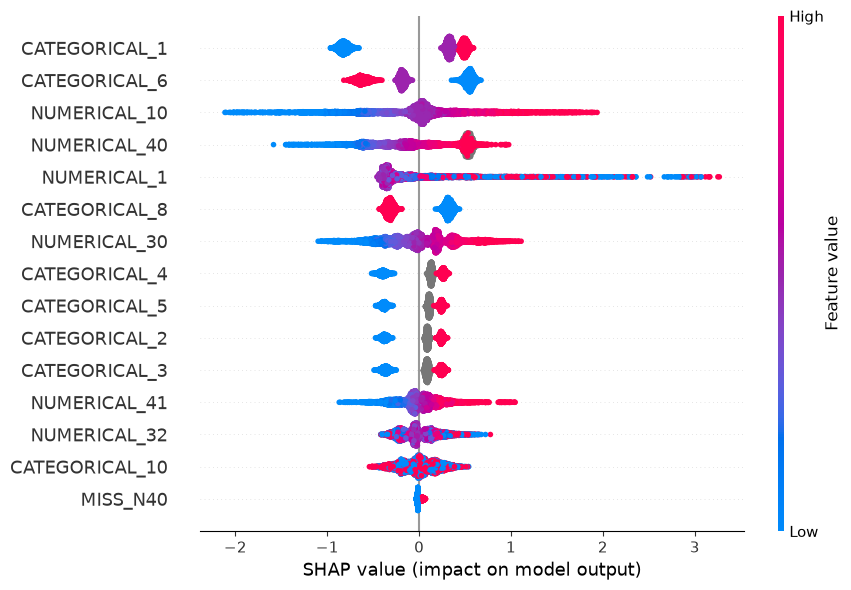

In [37]:
# --- 8.1 Gain importance vs SHAP (validation sample, so no holdout targets are involved) -------------------
import shap
rs = np.random.RandomState(1)
idx = rs.choice(len(X_va), 6000, replace=False)
Xs = X_va.iloc[idx]
sv = models["lgbm"].predict(Xs, num_iteration=models["lgbm"].best_iteration, pred_contrib=True)   # exact TreeSHAP, log-odds
shap_vals, base_val = sv[:, :-1], sv[0, -1]

imp = pd.DataFrame({"gain_share": pd.Series(models["lgbm"].feature_importance("gain"), LGB_FEATURES),
                    "mean_abs_shap": pd.Series(np.abs(shap_vals).mean(0), LGB_FEATURES)})
imp["gain_share"] /= imp["gain_share"].sum(); imp["shap_share"] = imp["mean_abs_shap"] / imp["mean_abs_shap"].sum()
imp["rank_gain"], imp["rank_shap"] = imp["gain_share"].rank(ascending=False), imp["shap_share"].rank(ascending=False)
display(imp.sort_values("shap_share", ascending=False).head(12).round(4))

Xs_plot = Xs.copy()
for c in CAT_COLS:
    if c in Xs_plot: Xs_plot[c] = Xs_plot[c].cat.codes.replace(-1, np.nan)
plt.figure(); shap.summary_plot(shap_vals, Xs_plot, max_display=15, show=False, plot_size=(9, 6)); plt.tight_layout(); plt.show()

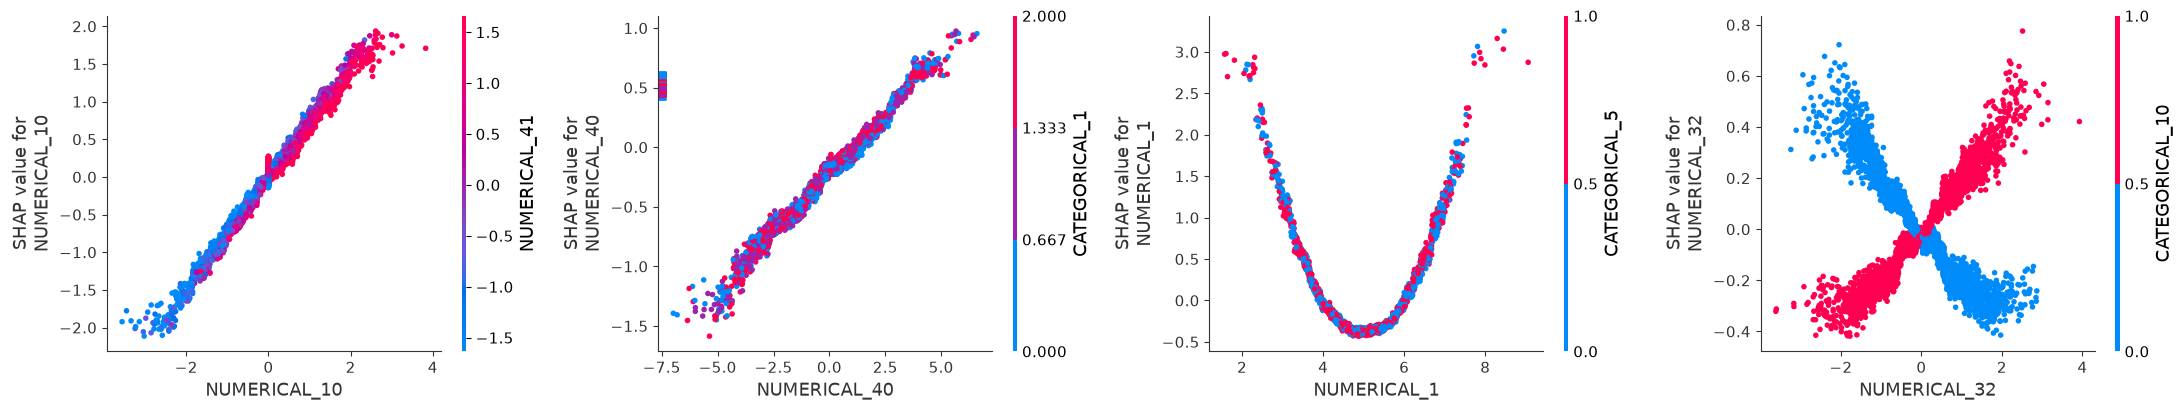

In [38]:
# --- 8.2 Dependence plots: 3 strongest numerics + the NUMERICAL_32 x CATEGORICAL_10 interaction ----------------
top_nums = [f for f in imp.sort_values("shap_share", ascending=False).index if f in NUM_COLS][:3]
fig, axes = plt.subplots(1, 4, figsize=(22, 4.2))
for ax, f in zip(axes, top_nums):
    shap.dependence_plot(f, shap_vals, Xs_plot, ax=ax, show=False)
shap.dependence_plot("NUMERICAL_32", shap_vals, Xs_plot, interaction_index="CATEGORICAL_10", ax=axes[3], show=False)
plt.tight_layout(); plt.show()

In [39]:
# --- 8.3 Two individual applications (adverse-action style explanation) --------------------------------
# Picked from the holdout by PREDICTED risk only (no target used).
pd_ho = preds["lgbm"]["holdout_cal"]
contrib = models["lgbm"].predict(X_ho, num_iteration=models["lgbm"].best_iteration, pred_contrib=True)
for label, i in [("LOWEST predicted risk", int(np.argmin(pd_ho))), ("HIGHEST predicted risk", int(np.argmax(pd_ho)))]:
    c = pd.Series(contrib[i, :-1], LGB_FEATURES)
    top = c.reindex(c.abs().sort_values(ascending=False).index)[:6]
    print(f"\n{label}: {holdout.iloc[i][ID_COL]}   calibrated PD = {pd_ho[i]:.3f}   (portfolio average log-odds = {contrib[i, -1]:.2f})")
    display(pd.DataFrame({"value": [X_ho.iloc[i][f] for f in top.index], "log-odds contribution": top.values.round(3),
                          "direction": np.where(top.values > 0, "raises risk", "lowers risk")}, index=top.index))


LOWEST predicted risk: 190078   calibrated PD = 0.001   (portfolio average log-odds = -0.85)


,value,log-odds contribution,direction
NUMERICAL_10,-2.161367,-1.392,lowers risk
CATEGORICAL_1,DVSOM,-0.751,lowers risk
NUMERICAL_30,-2.426053,-0.737,lowers risk
CATEGORICAL_6,C,-0.394,lowers risk
CATEGORICAL_5,TR,-0.360,lowers risk
NUMERICAL_41,-2.265519,-0.359,lowers risk



HIGHEST predicted risk: 193950   calibrated PD = 0.996   (portfolio average log-odds = -0.85)


,value,log-odds contribution,direction
NUMERICAL_1,1.78838,2.611,raises risk
NUMERICAL_10,0.956112,0.606,raises risk
CATEGORICAL_6,A,0.550,raises risk
NUMERICAL_40,NaN,0.449,raises risk
CATEGORICAL_1,OMFDE,0.376,raises risk
CATEGORICAL_5,TR,-0.336,lowers risk


### Reading the interpretation outputs

**Gain vs SHAP – where they disagree and why.** Both rankings are headed by the same variables (`CATEGORICAL_1`,
`CATEGORICAL_6`, `NUMERICAL_10`, `NUMERICAL_40`, `NUMERICAL_1`) but the order differs. *Gain* credits a feature for every split
it appears in, so it favours variables the trees must slice many times: `NUMERICAL_10` is 1st by gain (0.152) but 3rd by SHAP,
and `NUMERICAL_1` is 2nd by gain (0.119) but 5th by SHAP – a U-shaped variable needs many splits to describe its two arms,
which inflates gain without moving the average prediction as much. Binary categoricals show the opposite pattern: one split,
large and consistent effect, so they rank higher by SHAP (`CATEGORICAL_1` is 1st by SHAP, 3rd by gain). `NUMERICAL_32` does not
appear in the SHAP top 12 at all: its effect exists only *jointly* with `CATEGORICAL_10` (section 6.5) and flips sign between
the levels, so its average marginal contribution is small even though the 4th dependence panel shows a clear effect. SHAP is
the better guide to *how much a feature moves the score*; gain to *how much work the trees spent on it*.

**Top drivers in business language** (column names are anonymised, so we describe shapes, not meanings):

1. **`CATEGORICAL_1`** – one segment (`DVSOM`) is markedly safer (bad rate 23%) than the other two (41–44%).
2. **`CATEGORICAL_6`** – level `A` is the riskiest (45%), `C` the safest (25%).
3. **`NUMERICAL_10`** – risk rises steadily and almost linearly with the value; the lowest tenth of clients has a ~14% bad rate,
   the highest tenth ~62%. Widest effect range of any variable (≈ ±2 log-odds). For the ~31% of rows imputed with the median
   it contributes nothing.
4. **`NUMERICAL_40`** – risk increases roughly linearly with the value, and **a missing value is itself a risk signal**
   (45% bad rate when missing vs 32% when present).
5. **`NUMERICAL_1`** – a **U-shape centred at ≈ 5**: the safest clients sit near the typical value, risk climbs sharply the
   further the value is from 5 in *either* direction (below ≈ 3 or above ≈ 7 adds 2–3 log-odds), then plateaus.
6. **`CATEGORICAL_8`** – level `BB` is safer than `AA` (31% vs 41%).
7. **`NUMERICAL_30`** (and `NUMERICAL_41`) – monotone, moderate: higher value → higher risk.
8. **`CATEGORICAL_2..5`** (always missing together) – clients with *no value* in this block are riskier (42% vs 32%).
9. **`NUMERICAL_32` × `CATEGORICAL_10`** – a crossover: for one level of `CATEGORICAL_10` risk rises with `NUMERICAL_32`, for
   the other it falls (4th panel of the dependence plot: two mirror-image lines). Neither variable matters on its own.

**Plausibility.** The shapes are smooth and either monotone or a clean U – no jagged or oscillating curves, which is what
overfitting would look like. The U-shape of `NUMERICAL_1` is symmetrical and the interaction is a perfect X; both look like real
structure rather than noise. We did not add monotone constraints; `NUMERICAL_1` would be wrongly constrained if we had.

**Two individual explanations (log-odds contributions relative to a portfolio-average client).**
* *Lowest risk* (ID 190078, PD ≈ 0.1%): a very low `NUMERICAL_10` (−2.2) is the main reason (−1.39), followed by
  `CATEGORICAL_1 = DVSOM` (−0.75), a low `NUMERICAL_30` (−0.74), `CATEGORICAL_6 = C` (−0.39), `CATEGORICAL_5 = TR` (−0.36) and a
  low `NUMERICAL_41` (−0.36).
* *Highest risk* (ID 193950, PD ≈ 99.6%): a `NUMERICAL_1` of 1.8, far below the typical 5, adds +2.61 – the left arm of the U;
  then `NUMERICAL_10` (+0.61), `CATEGORICAL_6 = A` (+0.55), a missing `NUMERICAL_40` (+0.45) and `CATEGORICAL_1 = OMFDE` (+0.38);
  `CATEGORICAL_5 = TR` pulls the other way (−0.34).
  These are the "principal reasons" an adverse-action notice would cite.

## 9. Hand-off to Challenge 2 — `results/pd_predictions.csv`

Challenge 2 (Optimization) consumes your PDs directly. Get this file right:

- One row per **May 2015** application — all of them, no filtering.
- Exactly two columns: `ID_APPLICATION`, `PD`.
- `PD` is a **probability in [0, 1]** of `TARGET = 1` (default), from the model you selected.
- Prefer a **calibrated** PD. If your chosen model is poorly calibrated, calibrate it
  (isotonic or Platt) on the **validation split** — never on the holdout. Note the validation
  split is same-period, so it calibrates the *level* well but cannot correct drift between the
  development period and May 2015; check the holdout mean PD against the observed bad rate and say
  what you find.

In [40]:
# --- HELPER (given): submission writer with validation ----------------------
def save_pd_predictions(ids, pd_values, path="../results/pd_predictions.csv", expected_n=None):
    out = pd.DataFrame({"ID_APPLICATION": np.asarray(ids), "PD": np.asarray(pd_values, float)})
    assert out["ID_APPLICATION"].is_unique, "duplicate ID_APPLICATION"
    assert out["PD"].between(0, 1).all(), "PD outside [0, 1]"
    assert out["PD"].notna().all(), "PD contains NaN"
    if expected_n is not None:
        assert len(out) == expected_n, f"expected {expected_n} rows, got {len(out)}"
    import os
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    out.to_csv(path, index=False)
    print(f"saved {path}: {len(out):,} rows, mean PD = {out['PD'].mean():.4f}")
    return out

In [41]:
# --- 9.1 Final scoring: chosen model, Platt-calibrated on VALID ------------------------------------------
FINAL_MODEL = BEST
final_pd = preds[FINAL_MODEL]["holdout_cal"]
out = save_pd_predictions(holdout[ID_COL], final_pd, path="../results/pd_predictions.csv", expected_n=len(holdout))

# sanity checks required by the brief
print(f"model {FINAL_MODEL}: mean PD {final_pd.mean():.4f}  vs  observed May-2015 bad rate {y_ho.mean():.4f}  "
      f"(difference {final_pd.mean() - y_ho.mean():+.4f})")
print("raw (uncalibrated) mean PD:", round(preds[FINAL_MODEL]["holdout"].mean(), 4))
chk = pd.read_csv("../results/pd_predictions.csv")
assert list(chk.columns) == ["ID_APPLICATION", "PD"] and len(chk) == (df["MONTH"] == HOLDOUT_MONTH).sum()
assert set(chk["ID_APPLICATION"]) == set(holdout[ID_COL])
print("file check OK:", chk.shape, "| PD range", chk["PD"].min().round(4), "-", chk["PD"].max().round(4))

saved ../results/pd_predictions.csv: 17,976 rows, mean PD = 0.3605
model lgbm: mean PD 0.3605  vs  observed May-2015 bad rate 0.3629  (difference -0.0024)
raw (uncalibrated) mean PD: 0.3598


file check OK: (17976, 2) | PD range 0.0005 - 0.996


### What was written, and what the checks say

* `results/pd_predictions.csv`: **17,976 rows** (every May-2015 application), columns `ID_APPLICATION, PD`, no duplicates or NaN,
  PD between 0.0005 and 0.996. Model: LightGBM + Platt scaling fitted on the **validation** split.
* **Level check:** mean PD **0.3605** vs observed May-2015 bad rate **0.3629** (−0.0024, i.e. 0.24 pp low). Raw, uncalibrated mean
  PD is 0.3598, so Platt moved the level toward the target by 0.07 pp. The validation bad rate (0.3585) is 0.4 pp *below* May's,
  so the small shortfall is the month being slightly worse than the development average, not a modelling defect. The model does
  **not** systematically under-predict the holdout.
* **Shape check (deciles):** predicted and observed track each other closely over the full range (largest decile error 2.0 pp, in
  decile 5; riskiest decile 89.3% predicted vs 89.0% observed). The weak spot is the very safest decile: **predicted 2.0% vs
  observed 0.7%** – the model is conservative there. For Challenge 2 this slightly understates the profit of the safest
  loans and is worth knowing when reading the break-even PD.
* Calibration cannot repair drift: validation is same-period. The holdout evidence above is the only out-of-time check, and it
  is clean.

## 10. Conclusion & recommendation

**1. Algorithms compared.** (A) a **WOE logistic regression** (12 variables, additive, VIF ≤ 2.1, all coefficients with the expected
sign) – pros: explainable bin by bin, almost no overfitting (gap 0.005), good calibration; numerics are binned by coarse classing (36 of 42 collapse to a single
bin, 5 keep 8–10 bins); cons: additive, so it cannot see interactions – plain, it reached only Gini 0.602 on validation. (B) **LightGBM** (15 leaves, 671 rounds, lr 0.05) – pros: finds
non-linearity and interactions without manual work (Gini 0.683 validation / 0.701 holdout, KS 0.534); cons: harder to explain,
more overfit (gap 0.043) and needs calibration. The biggest single reason for the difference is one hidden *crossover
interaction* (`NUMERICAL_32` × `CATEGORICAL_10`): adding it as one engineered feature, which passed the same weekly stability test
as every other feature, lifts the scorecard to 0.671 (model A+), closing ~85% of the gap – a scorecard plus a few interactions is a
serious alternative.

**2. Feature stability.** The target is flat (~36% every month), so nothing at portfolio level signals trouble, yet three features
changed: **`CATEGORICAL_9` reversed its relationship with the target on 19-Apr-2015** (bad rate of `AA` 55% → 18%, `BB` 18% → 54%) with
*unchanged* level shares – PSI = 0.000 cannot see it, a weekly bad-rate-per-bin test can; **`CATEGORICAL_7` lost its riskiest level `A`**
(merged into `B`/`C`, PSI 6.5, 0% in May); and **`NUMERICAL_10` had a 3-month outage** (Nov-14 → Jan-15) but is fine in May. Rules
R1–R4 (section 2) were applied mechanically: `CATEGORICAL_9` and `CATEGORICAL_7` dropped; `NUMERICAL_10` kept, its outage months
excluded from the PSI base and its missing values replaced by the train median (no loss of validation Gini compared with leaving
them missing). In a pseudo-out-of-time test inside the development data, the model with all 53 features scores
**Gini 0.88 on a random split but 0.24 after 19-Apr**, while the stable feature set scores 0.68 / 0.70 – a random split would not
have caught either problem. We paid a price: dropping `CATEGORICAL_9` (IV 0.58, the strongest feature) is why the Gini is ~0.70
rather than the ~0.88 that the unscreened model appears to achieve.

**3. Holdout performance and deployment.** May-2015 (scored once): **Gini 0.701, AUC 0.851, KS 0.534**; drift gap −0.018 (no degradation; about 0.000 on the validation rows that have a real `NUMERICAL_10`, section 7.6), overfit gap 0.043; mean PD 0.3605 vs 0.3629 observed; the riskiest decile has an 89% bad rate and the top three
deciles capture 61% of all bads. **I would deploy it, conditionally**, with this monitoring: (i) *weekly* relationship-drift
(R2) and PSI on every feature including the engineered interaction – the R2 test is the one that would have caught
`CATEGORICAL_9`; (ii) missing-rate alarms per field (the `NUMERICAL_10` outage) and an alarm on any new/vanished category level
(`CATEGORICAL_7`); (iii) monthly Gini and predicted-vs-observed bad rate (trigger: Gini < 0.62 or mean PD off by more than 2 pp);
(iv) keep model A+ as a challenger. The holdout is a single month, so "no drift" is one observation, not a guarantee.

**4. With one more week.** (a) Ask the data owner what happened to `CATEGORICAL_9` and `CATEGORICAL_7`: if the 19-Apr flip is a
confirmed re-coding, *repair* it (swap the levels after that date) and recover the strongest feature – this is the largest
potential gain, and the one I deliberately did not gamble on. (b) Search for interactions systematically (SHAP interaction
values / pairwise screens, with a multiple-testing guard) instead of the one found by hand, and see how close a scorecard can
get. (c) Tune the coarse-classing settings (the 10-bin cap binds on 3 of the 5 informative numerics and the 5% minimum bin share blurs the
extreme tails of the U-shaped `NUMERICAL_1`).
(d) Check whether the conservatism in the safest decile matters for Challenge 2's break-even PD and, if so, calibrate with isotonic
regression in the low-PD range. (e) Quantify score uncertainty (bootstrap Gini intervals) and test monotone constraints.
**Weaknesses to be honest about:** the drop thresholds (PSI 0.25, drift 0.10) are conventional rather than tuned; the
pseudo-OOT test has only 6.9k rows; only one holdout month exists; the interaction was found by looking at LightGBM/SHAP output
on train (so the validation Gini of model A+ is not fully independent of that choice); median imputation puts ~31% of the
development rows on one value, so those rows carry no information from the strongest feature; the coarse-classing settings
(p < 0.001, ≤ 10 bins, ≥ 5% per bin) are conventional, not tuned; and the hyper-parameter search was small.